<a href="https://colab.research.google.com/github/FURKANNALBANTOGLU/smart-meter-data-analytics/blob/main/smart_meter_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# MIT License
#
#@title Copyright (c) 2021 CCAI Community Authors { display-mode: "form" }
#
# Permission is hereby granted, free of charge, to any person obtaining a
# copy of this software and associated documentation files (the "Software"),
# to deal in the Software without restriction, including without limitation
# the rights to use, copy, modify, merge, publish, distribute, sublicense,
# and/or sell copies of the Software, and to permit persons to whom the
# Software is furnished to do so, subject to the following conditions:
#
# The above copyright notice and this permission notice shall be included in
# all copies or substantial portions of the Software.
#
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
# IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL
# THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
# LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING
# FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER
# DEALINGS IN THE SOFTWARE.

# **CCAI Tutorial:**
# Smart Meter Data Analytics: Practical Use-Cases and Best Practices of Machine Learning Applications for Energy Data in the Residential Sector

**Authors:**
* Tobias Brudermüller (Brudermueller), Bits to Energy Lab, ETH Zurich, tbrudermuell@ethz.ch
* Markus Kreft, Bits to Energy Lab, ETH Zurich, mkreft@ethz.ch

**Supervisors:**
* Prof. Dr. Elgar Fleisch, Bits to Energy Lab, ETH Zurich & University of St. Gallen
* Prof. Dr. Thorsten Staake, Bits to Energy Lab, ETH Zurich & University of Bamberg

**Funding:**
- The authors note that their research in smart meter data analytics is funded by the Swiss Federal Office of Energy under grant number SI/502257 and SI/502271.

This notebook is part of a series of tutorials at the [ICLR 2023 Workshop on Tackling Climate Change with Machine Learning](https://www.climatechange.ai/events/iclr2023).

# **Key Learning Objectives** 🎯
In this tutorial, we provide a practical guide to current trends in smart meter data analytics. In particular, we focus on feature engineering and machine learning scenarios for energy data. During this tutorial:

- You will gain insights into current trends and use cases in the energy space.
- You will learn best practices for energy data visualization.
- You will apply both machine learning approaches and data mining techniques to real-world energy data.
- You will get a sense of typical and atypical energy use in a residential building.

In addition, some concepts offer the possibility of being applied to other time series data outside of the energy domain.

**Note:** We would also like to point out that some utilities allow their customers access to their own smart meter data either through customer portals or upon request. If you have an active smart meter at home, you can use this guide as a starting point for analyzing your own energy usage.

### **Abstract:**
To cope with climate change, the energy system is undergoing a massive transformation. Due to the electrification of all sectors, the power grid is facing high additional demand. As a result, the digitization of the grid is increasingly gaining attention. The smart grid relies heavily on the increasing deployment of smart meters around the world. The corresponding smart meter data is typically a time series of power or energy measurements with a resolution between 1 s and 60 min. This data provides valuable insights and opportunities for monitoring and controlling activities on the power grid.

In this tutorial, we therefore provide an overview of best practices for analyzing smart meter data. We focus on machine learning applications and low resolution (15 min) energy data in a residential setting. We use only real-world data and cover use cases that are highly relevant to practical applications. Although this tutorial is specifically tailored for an energy audience, we believe that anyone in the data analytics and machine learning field can benefit from it, as many techniques are applicable to all time series data. Through our tutorial, we hope to foster new ideas, contribute to interdisciplinary exchange between different research fields, and educate people about energy use.

### **Target Audience:**
In the best case, you have already worked with Python and have some basic knowledge of machine learning. Nevertheless, this tutorial can be completed and understood by anyone with basic programming skills.

- If you are a **student**, this tutorial will provide you with a practical introduction to applying machine learning to time series data.
- If you are a **researcher in machine learning**, you can use this tutorial to find ideas for your research and potential data sets for benchmarking.
- If you work for a **utility**, this tutorial will provide you with an overview of practical use cases and the current state of the art in smart meter data analytics.
- If you are an **individual** interested in energy-related topics, you can learn more about smart grid applications and energy consumption in this tutorial.

<a name="introduction"></a>
# **1. Introduction to smart meter data** 🔌

<a name="what_is_smd"></a>
### **1.1 What is smart meter data?**

The name **smart meter data (SMD)** comes from its measuring device - a so-called **smart meter**. This is a connected electricity meter that measures and transmits information about the electricity consumption of the building or apartment in which it is installed. Most smart meters provide time series data with a resolution of a few minutes to hours.

<a name="climate_change_relevance"></a>
### **1.2 Relevance for tackling climate change**
In [15], the International Energy Agency (IEA) summarizes the **status quo and current trends of the energy transition**. According to this article [15], global energy-related emissions will reach an all-time high of 36.6 Gt in 2021. With particular focus on electricity generation, distribution and demand, the following can be observed:

- **Increasing electricity demand:** The IEA expects global electricity demand to increase by 25-30% by 2030, partly due to more electric motors, electric vehicles, heat pumps, and hydrogen production [15], but generally due to electrification in all sectors.
- **Increasing share of renewables:** While most of the world's electricity still comes from fossil fuels, faster adoption of renewables is not only needed but already happening [15].  
- **Energy efficiency needed:** To meet the increasing demand for electricity from renewables, new technologies and efficiency measures are needed to reduce the amount of energy required per good or service [15].
- **Expanding access to electricity:** As of 2019, 770 million people still did not have access to electricity [15]. As stated in the United Nations Sustainable Development Goals (SDGs), everyone should have access to electricity, which requires even more effort on all of the above.

In order to achieve net zero emissions by the middle of the century, the energy sector is currently undergoing a massive transformation. This also requires digitization of the power grid to ensure a stable power supply for the energy-hungry modern society. In this context, **smart metering infrastructure plays a critical role in combating climate change** by enabling more efficient use of energy resources and reducing carbon emissions, in particular for:

- **Accurate monitoring:** Smart meters can provide feedback (in real time) to individuals and businesses on energy consumption. This has been shown to have a strong impact on behavioral changes in energy consumption [16, 17, 18].
- **Demand response:** Smart meters enable demand response programs, where consumers are incentivized to reduce their energy consumption during peak periods. This can help utilities reduce the need for expensive and carbon-intensive infrastructure that is only needed to meet peak demand [22].
- **Renewable energy integration:** By providing real-time data on energy demand and supply, smart meters can help utilities balance the grid and ensure that renewable energy sources are used efficiently [20].
- **Energy Efficiency:** Smart meters can help identify areas where energy is being wasted or used inefficiently. This can lead to lower carbon emissions and a more sustainable energy system [19, 21].


<a name=chances_limitations></a>
### **1.3 Chances and limitations**

Despite some challenges in deploying smart metering systems, smart meter data has the potential to bring significant benefits to households, businesses, and utilities.

**Opportunities and benefits:**
- More accurate data compared to traditional analog meters
- Can help understand energy use and promote energy efficiency
- Can increase customer engagement and lead to energy and cost savings
- Can improve billing accuracy
- Provides capabilities to monitor and control activity on the electric grid
- Can help optimize power distribution and increase power grid stability

**Limitations:**
- Secure data management must be in place, as smart meter data is sensitive information and some customers may have privacy concerns *(for more information, see [24]: Data protection impact assessment for smart grid and smart metering environment by the European Commission)*
- Requires significant investment from utilities and customers, as smart meters and related infrastructure can be expensive to install and deploy
- Smart meters can be compromised by errors in data collection.
- Contextual information is often required to interpret data.
- The type and resolution of measurements can vary, leading to challenges in data analysis

<a name=power_vs_energy></a>
### **1.4 Power vs. energy measurements**

Without getting too technical in the sense of energy science, it is important to note that the term smart meter data can refer to different types of measurements. Specifically, our smart meter will measure different variables and for our case the most important is Active Power.

**We further note that in the following, we mostly refer to energy data, but for simplification sometimes transform the data into approximations of average power by using multiplication factors.**

<a name=data_resolution></a>
### **1.5 Data resolution**
Resolution refers to the frequency with which data is recorded and transmitted. For smart meter data, it can range from **low resolution data** that is recorded only once per day or less frequently to **high resolution data** that is recorded several times per hour or even more frequently.
Resolution depends on several factors, including the meter itself, the utility's data management, the desired use case, and most importantly, the communication channel for the data. For example, in more rural areas, data may be transmitted over the power line, which requires a lower resolution [2]. The **most typical resolutions** are: 15-minute, 30-minute, 1-hour, 1-day, or 1-second.

**Only low-resolution data is used in this tutorial**, as this is the most common case and high-resolution data can be downsampled.

<a name=data_availability></a>
### **1.6 Data availability**

**Hundreds of millions of smart meters have already been installed worldwide, and deployment continues.** In 2016, 71 million smart meters were already installed in the United States, covering nearly half of all U.S. electricity customers [3]. Deployment in key Asian markets (China, India, Japan, and South Korea) is also growing rapidly. In 2019, total smart meter penetration in this region was 69% (653.3 million units), and 572.3 million additional units are expected to be installed between 2021 and 2025 [4]. In the European Union, most countries are expected to reach a deployment rate of at least 80% during 2020-2025, while some countries are already using second-generation devices [5]. This means that the rollout of smart meters is still ongoing and is a continuous effort.

**The following must therefore be taken into account** when analyzing smart meter data:
- **Different start times:** Smart meters are installed and activated at different times, i.e., individual time series of households have different start times.
- **Different end times:** Smart meter data is usually identified by a customer and a location, i.e. individual time series may end at different times, e.g. when a customer changes location.
- **Missing data:** Smart meters may experience outages, i.e., gaps may occur in some time ranges of the time series. For example, if outages vary significantly within a studied population, this makes it difficult to compare households in terms of annual energy consumption.
- **Erroneous readings:** Smart meters can have errors and transmit data that is not meaningful. We recommend always being critical and reasoning carefully. Check and discuss with colleagues and peers whether your interpretations seem reasonable.
- **Multiple Smart Meters:** In most cases, a single smart meter measures all appliances in a household. However, sometimes more than one smart meter is installed in a building to measure appliances separately (e.g., when special tariffs are offered).

See the [section on smart meter data pre-processing](#preprocessing_smd) to learn how to handle these aspects to make data from different households comparable.


<a name=context_and_domain_knowledge></a>
### **1.7 Contextual information and domain knowledge**

**There are many factors that influence energy consumption, such as**:
- Building type (e.g., apartment vs. single-family home).
- Size of the building
- Building insulation (often depends on the age of the building)
- Number of occupants
- Type of equipment (e.g., electric vehicle present or not)
- Building is heated electrically (e.g., with a heat pump) or with fossil fuels
- Electric or non-electric water heating
- Installation of a photovoltaic (PV) system

This means that the smart meter data can vary significantly depending on these factors. For example, a household may triple its annual energy consumption by installing a heat pump. **We recommend that when working with smart meter data, you try to get as much contextual information as possible.** Often this requires the use of additional data sources. The more you work with smart meter data, the more you will get a sense of its patterns, which will allow you to better interpret data without context. For example, in a [later section on load disaggregation](#nilm) you will see that device installations behave quite differently, and in [another section](#anomaly_detection) you will learn how to find anomalies in smart meter data.


<a name=using_additional_data_sources></a>
### **1.8. Making use of additional data sources**

As mentioned in the previous section, contextual information can help to interpret smart meter data correctly and make it comparable between households. For example, to identify patterns that are specific to a particular group of households, you can use survey data, as is often done in research projects. Alternatively, you can look for publicly available data sources that can provide context. However, this often requires knowledge of the exact address of each location to be studied and some additional effort to automate the search for contextual information. **Useful data sources may include:**
- Weather data services
- Data sets on PV installations
- Local or national geographic information systems  
- National building register databases

[Bring me back to the outline](#outline)

<a name=tutorial_preparations></a>
# **2. Preparations for the project homework**
For this tutorial to work, we need to import some packages and of course some smart meter data.
Even if you only want to work on some sections of the tutorial, you should run the cells provided in this chapter beforehand.

<a name=package_imports></a>
### **2.1 Importing Packages**

First, we **install and import the necessary Python packages**. Other potentially useful software tools that we do not use in this tutorial can be found in one of the last sections on [additional resources](#resources_software).

In [3]:
%%capture
!pip install ruptures
!pip install saxpy
!pip install tsfresh

In [4]:
# basic packages
import pandas as pd
import numpy as np
import datetime as dt
from pytz import timezone
import urllib
import os
import math
from scipy import stats
from scipy.signal import find_peaks, spectrogram

# packages for visualizations
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# package for change point detection
import ruptures as rpt

# package for SAX
from saxpy.hotsax import *
from saxpy.sax import sax_via_window

# package for feature training
import tsfresh

# sklearn packages
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans

# set global variables about the time-zone (used by pandas and matplotlib)
TZ_LOCAL = 'Europe/Bucharest'
plt.rcParams['timezone'] = TZ_LOCAL
plt.rcParams['figure.dpi'] = 100

In [5]:
# ---------------------
# DEFINE HELPER METHODS
# ---------------------

def handle_timezones(P_smx):
  '''
    Sets local timezones on data frames of smart meter and weather data.
    Args:
      df_smd: data frame holding smart meter data
      df_weather_daily: data frame holding daily temperature readings
      df_weather_hourly: data frame holding hourly temperature readings
  '''
  P_smx.index = pd.to_datetime(P_smx.index, format='%Y-%m-%d %H:%M:%S').tz_convert(TZ_LOCAL)

  # handle time zones
  handle_timezones(P_smx)

  return P_smx

In [6]:
# ------------------------
# DEFINE HELPER FUNCTIONS
# ------------------------

def plot_data(ax, df, column='P'):
  if column is None:
    ax.plot(df)
  else:
    ax.plot(df[column])
  ax.xaxis.set_tick_params(rotation=45)
  ax.set_xlabel('Time')
  ax.set_ylabel('Energy (kWh)')
  ax.grid()

def calculate_daily_consumption(df, column='Value'):
  return df.groupby([df.index.date])[column].sum()

def plot_daily_consumption(ax, df):
  # Divide by 4 to convert 15 Wmin to 1 Wh
  ax.plot(df)
  ax.xaxis.set_tick_params(rotation=45)
  ax.set_xlabel('Day')
  ax.set_ylabel('Energy (kWh)')
  ax.set_title('Total daily consumption')
  ax.grid()

def calculate_mean_profile(df, column='Value'):
  mean_profile = df.groupby([df.index.time])[column].mean()
  mean_profile.index = mean_profile.index.map(lambda t: dt.datetime.combine(dt.datetime(year=1970, month=1, day=1), t))
  return mean_profile

def plot_mean_profile(ax, mean_profile):
  ax.plot(mean_profile)
  ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))
  ax.set_xlabel('Hour')
  ax.set_ylabel('Energy (kWh)')
  ax.set_title('Mean consumption profile')
  ax.grid()

<a name=data_imports></a>
### **2.2 Importing the data**

Next, we import some **smart meter data in 15-minute resolution**, which will serve as **example** in this tutorial. This data comes from real households in Switzerland and is provided by a local utility company. We have four households, each with two separate smart meters. All households have a heat pump installed for heating purposes, which is measured by one separate smart meter. All other appliances are measured by the second smart meter. In addition to the smart meter data, we also load temperature measurements from a nearby weather station. We will use this data in later sections of this tutorial.

If you would like to apply what you have learned in this tutorial to alternative, publicly available data sets yourself, you can find some references in a [section at the end of this tutorial](#resources_data_sets).

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
smx1=pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/data_files/Log1-UPB-SUBM1-20260105.txt.zip", delimiter="\t", on_bad_lines='skip', low_memory=False)
smx2=pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/data_files/Log1-UPB-SUBM1-20260106.txt.zip", delimiter="\t", on_bad_lines='skip', low_memory=False)
smx3=pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/data_files/Log1-UPB-SUBM1-20260107.txt.zip", delimiter="\t", on_bad_lines='skip', low_memory=False)
smx4=pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/data_files/Log1-UPB-SUBM1-20260108.txt.zip", delimiter="\t", on_bad_lines='skip', low_memory=False)
smx5=pd.read_csv("/content/drive/MyDrive/Colab_Notebooks/data_files/Log1-UPB-SUBM1-20260109.txt.zip", delimiter="\t", on_bad_lines='skip', low_memory=False)

In [9]:
P_smx_t1 = smx1[['SysDate','P']]
P_smx_t2 = smx2[['SysDate','P']]
P_smx_t3 = smx3[['SysDate','P']]
P_smx_t4 = smx4[['SysDate','P']]
P_smx_t5 = smx5[['SysDate','P']]

P_smx1=smx1['P']
P_smx2=smx2['P']
P_smx3=smx3['P']
P_smx4=smx4['P']
P_smx5=smx5['P']

In [10]:
date1=smx1['SysDate']

In [11]:
P_smx = pd.concat([P_smx_t1, P_smx_t2, P_smx_t3, P_smx_t4, P_smx_t5], ignore_index=True)
P_smx['SysDate'] = pd.to_datetime(P_smx['SysDate'], errors='coerce')
P_smx = P_smx.dropna(subset=['SysDate'])
P_smx['SysDate'] = P_smx['SysDate'].dt.strftime('%Y-%m-%d %H:%M:%S')

In [12]:
t = np.arange(0, 24, 1/3600)

In [13]:
P_smx1

,P
0,2210.0
1,2200.0
2,2200.0
3,2210.0
4,2210.0
...,...
86395,2020.0
86396,2020.0
86397,2020.0
86398,2020.0


### **Data Structure Analysis: High-Resolution Time Series**

**📌 Comments on the Numerical Results:**

The output of the DataFrame (`P_smx1`) reveals critical information about the fundamental structure and resolution of our smart meter dataset before any visualization takes place:

* **Data Granularity (1-Hz Sampling Rate):** The DataFrame contains exactly **86,400 rows** for a single day. Since there are 86,400 seconds in a 24-hour period ($24 \text{ h} \times 60 \text{ min} \times 60 \text{ s}$), this mathematically confirms that our smart meter is recording active power (`P`) at a highly granular 1-second interval (1 Hz).
* **Initial Power Baseline:** The numerical preview shows starting active power values around 2200-2210. This gives us an immediate quantitative baseline for the household's power draw at the very beginning of the recorded period.

> **Conclusion:** Confirming the 86,400-row structure is vital. Standard utility meters often record at 15-minute intervals (yielding only 96 rows per day). Having 86,400 data points per day is what makes the subsequent Digital Signal Processing (DSP) and high-frequency event detection (identifying individual appliance switches) mathematically possible in this project.

Let's take a look at the data frame that contains the smart meter data.
The index of the frame contains the timestamps of the measurements.
There are three columns of energy values that reflect the total consumption in kilowatt hours (kWh) for each 15-minute time interval:
- **Value_HeatPump:** Consumtion of the heat pump measured by one smart meter
- **Value_OtherAppliances:** All other consumption in the household measured by a second smart meter
- **Value:** Sum of both measurements reflecting the total consumption

For now we will focus on the **total consumption**.

[link text](https://)Let's also look at the **daily and hourly weather data**. In the daily data frame, we have three columns for the minimum, maximum and average temperature in degrees Celsius (°C) on each day. The hourly data frame contains a single column with the temperature at each hour.

In [14]:
min_len = min(len(P_smx1), len(P_smx2), len(P_smx3), len(P_smx4), len(P_smx5))
p_all_day = np.vstack((
    P_smx1[:min_len],
    P_smx2[:min_len],
    P_smx3[:min_len],
    P_smx4[:min_len],
    P_smx5[:min_len]
)).T

p_all_day.shape

(86053, 5)

In addition, for [later use in the context of clustering](#clustering_algorithms), we **load data of average daily profiles that we extracted for a few hundred households**.

<a name=visualizing_smd></a>
# **3. Best practices for visualizing smart meter data** 🎨

Now that the data is loaded, let's examine it and get a feel for it. Instead of just printing out the values, it is very useful to display them graphically. This allows us to see patterns and behaviors quickly and intuitively. So here are some starting points and best practices for visualizing smart meter data.

<a name=time_series_visualizations></a>
### **3.1 Time-series visualizations of energy data**

The easiest way to display the data is in a **one-dimensional line chart** that shows the entire time span.
It is easy to see the range of data availability as well as the maximum values.
Large-scale trends within the data can also be seen.
However, this **visualization is too dense to observe more detailed behavior** and relate it to specific timestamps.

To solve this problem, we need calculate the power profile on each day by avereging over 15 minutes and over 1h. Now we can see clear trends across seasons.

We can also reduce the density of the plot by only visualizing one week of data. Here we can see regular patterns that seem to repeat each day.

Another insightful way to examine such regularities is to **calculate the mean consumption profile by averaging the consumption at each time of day** over the entire period of measurements. Here we can clearly see a peak of increased consumption at night.

### 1. Plot all days in one graph, one after another - with 1s resolution
### 2. Plot all days in one graph, one after another - 1h resolution

<a name=visualizing_distributions></a>
### **3.2 Visualizing distributions of power profile**

While it is very interesting to observe the evolution of power profiles over time, it can also be informative to analyze **how often how much power is used, i.e. the histogram of the values in the time series**.

In most cases, consumption is very low and the distribution falls off rapidly as energy increases.
However, there are peaks in the distribution that indicate recurring measurements with the same energy. These are indications of regularly running devices (see [later section](#distributional_peak_detection) in the context of pre-processing).

Plotting the distribution with a logarithmic scale of the y-axis reveals peaks with lower counts at higher energy.

In [15]:
bins = np.linspace(0, 2.5, 100)
display(bins)
bins.shape

array([0.        , 0.02525253, 0.05050505, 0.07575758, 0.1010101 ,
       0.12626263, 0.15151515, 0.17676768, 0.2020202 , 0.22727273,
       0.25252525, 0.27777778, 0.3030303 , 0.32828283, 0.35353535,
       0.37878788, 0.4040404 , 0.42929293, 0.45454545, 0.47979798,
       0.50505051, 0.53030303, 0.55555556, 0.58080808, 0.60606061,
       0.63131313, 0.65656566, 0.68181818, 0.70707071, 0.73232323,
       0.75757576, 0.78282828, 0.80808081, 0.83333333, 0.85858586,
       0.88383838, 0.90909091, 0.93434343, 0.95959596, 0.98484848,
       1.01010101, 1.03535354, 1.06060606, 1.08585859, 1.11111111,
       1.13636364, 1.16161616, 1.18686869, 1.21212121, 1.23737374,
       1.26262626, 1.28787879, 1.31313131, 1.33838384, 1.36363636,
       1.38888889, 1.41414141, 1.43939394, 1.46464646, 1.48989899,
       1.51515152, 1.54040404, 1.56565657, 1.59090909, 1.61616162,
       1.64141414, 1.66666667, 1.69191919, 1.71717172, 1.74242424,
       1.76767677, 1.79292929, 1.81818182, 1.84343434, 1.86868

(100,)

In [16]:
bins = np.linspace(0, 1, 1000)

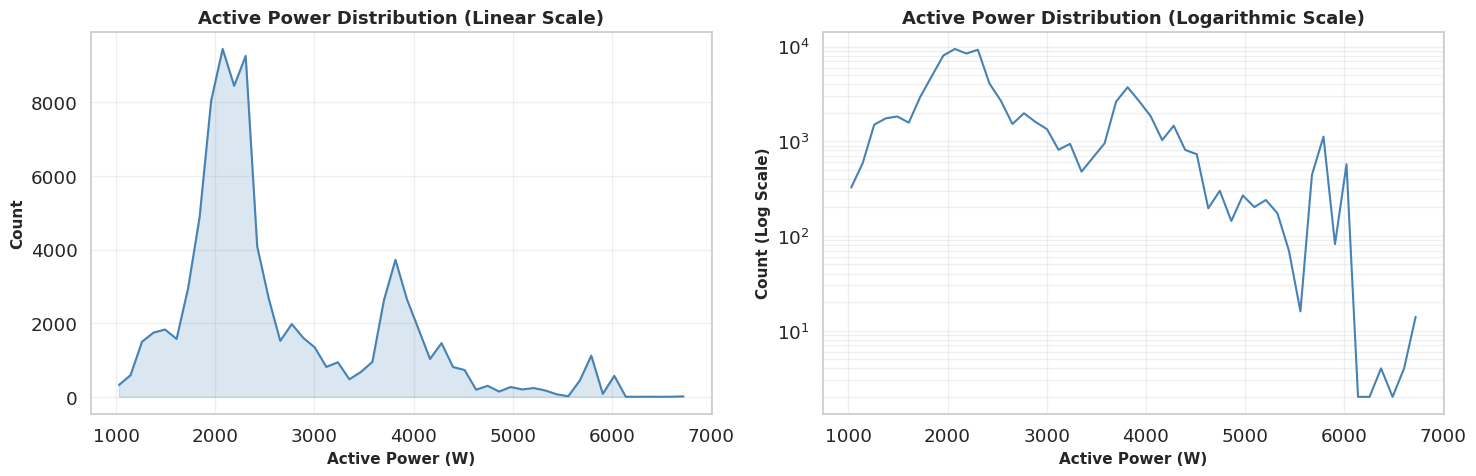

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Clean data (drop NaNs if any)
data = P_smx1.dropna().values.astype(float)

# Calculate histogram dynamically across the actual power range
df_smd_hist, bin_edges = np.histogram(data, bins=50)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Create figure with two columns (Linear vs. Log scale)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# 1. Linear scale histogram
ax[0].plot(bin_centers, df_smd_hist, color='steelblue', linewidth=1.5)
ax[0].fill_between(bin_centers, df_smd_hist, color='steelblue', alpha=0.2)
ax[0].set_title('Active Power Distribution (Linear Scale)', fontsize=13, fontweight='bold')
ax[0].set_xlabel('Active Power (W)', fontsize=11, fontweight='bold')
ax[0].set_ylabel('Count', fontsize=11, fontweight='bold')
ax[0].grid(alpha=0.3)

# 2. Logarithmic scale histogram
ax[1].plot(bin_centers, df_smd_hist, color='steelblue', linewidth=1.5)
ax[1].set_yscale('log')
ax[1].set_title('Active Power Distribution (Logarithmic Scale)', fontsize=13, fontweight='bold')
ax[1].set_xlabel('Active Power (W)', fontsize=11, fontweight='bold')
ax[1].set_ylabel('Count (Log Scale)', fontsize=11, fontweight='bold')
ax[1].grid(which='both', alpha=0.3)

plt.tight_layout()
plt.show()

### **Figure 1: Active Power Consumption Histogram Analysis (Dataset: 31)**

This histogram illustrates the probability distribution of the active power (P) consumption for household 31, recorded at a high temporal resolution (second-by-second) over a 5-day period.

Upon analyzing the data, a clear **bimodal distribution** is observed:

1. **First and Main Peak (2000 - 2500 W):** The highest frequency of occurrences is concentrated in this region. This indicates that the household continuously consumes this level of power in the background for the vast majority of the day. This level represents the system's **"Baseload"** (e.g., continuously running refrigerator, router, devices on standby, and potentially baseline heating elements).

2. **Second Peak (3800 - 4000 W):** Moving to the right, a secondary concentration area forms around 4000 W. This represents the consumption periods during peak hours when the residents are active and switch on high-power appliances (such as the oven, washing/dishwashing machine, kettle, or heat pump).

**Conclusion:** This high-resolution dataset allows us to clearly distinguish the household's underlying energy consumption habits and the power characteristics of their specific appliances.

<a name=multidimensional_visualizations></a>
### **3.3 Multi-dimensional visualizations**

The simple line graphs can be advantageous for plotting average data or short periods of time (e.g., a few days). However, observing longer periods in this way is difficult due to the density of the measurements. In the case of smart meter data, we are particularly interested in observing the behavior of prominent appliances and their regular on/off switching per day. **Heatmaps** are a very powerful method to visualize the corresponding time series patterns in a multidimensional way.

To achieve this, we **divide** each timestamp into day and time, which can be interpreted as transferring time in one dimension into a **two-dimensional space**. Consequently, the axes of the heatmap are as follows:
- **x-axis:** shows the date in chronological order from left to right.
- **y-axis:** shows the time of day in chronological order from top to bottom.

Now you can interpret the area spanned by x and y as a canvas that you can color according to the patterns generated by the smart meter data:
- The **position of each pixel** in the canvas is indicated by the date and time (i.e., the timestamp).
- The **color of each pixel** is defined by a mapping of the energy consumption at the given time to a continuous color scale.

Let's take a look at what that looks like!

## Task 3.3.1 Please create a HEATMAP based on the values of the 5 files avereged over 1h and 15 min (please use Lab 2 for help)

---------------------------------------

Now we can see **patterns in the data over the entire time span** across both, seasons and hours of the day:
- activity is higher in winter than in summer because there is no heating in summer
- there seems to be a device that turns on very regularly every day
- the checkerboard pattern especially visible in winter is caused by a heat pump *(check out [6] if you want to learn more about its patterns in smart meter data)*.

We can also **visualize the heatmap data in a three-dimensional representation** that makes the consumption peaks even clearer.

# Task 3.3.2 Please create the 3D HEATMAP based on the values of the files avereged over 1h and 15 min (use the example below)

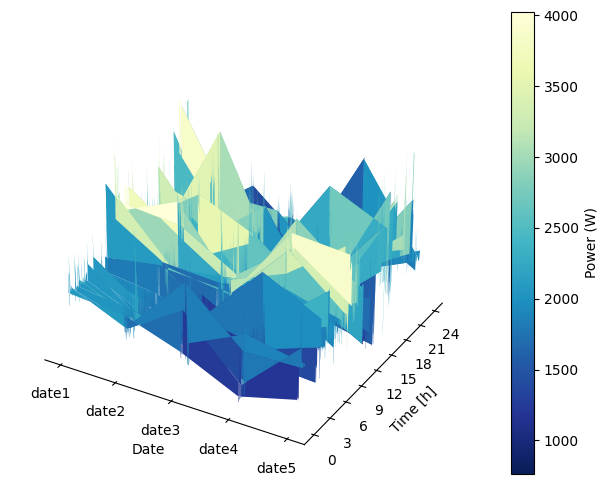

In [18]:
fig = plt.figure(figsize=(10, 6))
ax = plt.subplot(111, projection='3d')
# Create meshgrid
X, Y = np.meshgrid(np.arange(p_all_day.shape[1]), np.arange(p_all_day.shape[0]))

p_all_day = pd.to_numeric(p_all_day.ravel(), errors='coerce').reshape(p_all_day.shape)
p_all_day = np.nan_to_num(p_all_day)

plot = ax.plot_surface(X, Y, p_all_day, cmap='YlGnBu_r')
# set tick every three hours for the time axis
ax.set_yticks(ticks=range(0, 86401, 3*3600))          # every hour (0, 3600, ..., 86400)
ax.set_yticklabels(labels=range(0, 25, 3))           # hours: 0 to 24
ax.set_ylabel('Time [h]')

#for the date part
date_labels = ['date1', 'date2', 'date3', 'date4', 'date5']
ax.set_xticks(range(len(date_labels)))
ax.set_xticklabels(date_labels, rotation=0)
ax.set_xlabel('Date')

# Remove gray panes and axis grid
ax.xaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('white')
ax.yaxis.pane.fill = False
ax.yaxis.pane.set_edgecolor('white')
ax.zaxis.pane.fill = False
ax.zaxis.pane.set_edgecolor('white')
ax.grid(False)
# Remove z-axis
ax.zaxis.line.set_lw(0.)
ax.set_zticks([])
# ax.set_zlabel('Energy (kWh)')

fig.colorbar(plot, ax=ax, label='Power (W)')

fig.show()

### **Figure 2: 3D Surface Spatiotemporal Analysis of Power Consumption**

This 3D surface plot provides a spatiotemporal visualization of the household's active power demand across the 5-day observation period.

* **Axes Description:** The X-axis represents the sequential days (`date1` to `date5`), the Y-axis denotes the time of day (0 to 24 hours), and the Z-axis (coupled with the color map) indicates the magnitude of Active Power in Watts.

**Key Analytical Observations:**

1. **Consistent Baseload (The Blue Valleys):** The extensive dark blue and teal regions forming the "floor" of the graph perfectly align with the findings from the previous histogram. These areas represent the continuous ~2000-2500 W baseload. The visual consistency of these valleys across all 5 days confirms that the background energy consumption is highly stable regardless of the specific day.
2. **Dynamic Peak Demands (The Yellow Peaks):** The sharp yellow and light green spikes indicate sudden, high-power consumption events approaching 4000 W. Unlike the stable baseload, these peaks are highly dynamic. By analyzing the Y-axis (Time), we can identify specific clustering of these high-demand periods, which correspond to active hours when major appliances are operated by the residents.

**Conclusion:** The 3D mapping effectively transitions our analysis from a purely statistical view (histogram) to a chronological profile, clearly illustrating the household's daily rhythm and peak-hour behavioral patterns.

<a name=preprocessing_smd></a>
# **4. Pre-processing smart meter data** 🛠️

In some cases, it may be necessary to pre-process the data for analysis. In this section we present some best practices to be used in later sections.

<a name=outlier_detection_hampel></a>
### **4.1 Outlier detection with Hampel filter**

**Outlier detection methods are suitable for detecting unrealistic measurements.**

**Hampel filtering** is such a method to detect outliers based on a sliding window approach in which data points are compared to the distribution of their neighbors.
The method has two parameters:
- `window size` controls the size of the neighborhood to be considered for the distribution
- `n_sigmas` determines how far out of the distribution a point must fall, to be considered an outlier

Together, the parameters can be used to set the aggressiveness of the filtering. When a data point is detected as an outlier, its value is replaced by the median of its neighbors' distribution.

# Task 4.1. Please use the code in lab2 to apply Hampel Fileter on all your files


<a name=simple_baseload_estimation></a>
### **4.2 Simple baseload estimation**

The term **baseload refers to the minimum amount of electricity that a household or building uses on a fairly continuous basis**. It is independent of whether or not someone is actively using appliances or electronics. For example, it can be caused by heating and cooling systems, refrigerators, or other major appliances that run continuously even when no one is home. Normally, the baseload is relatively stable from day to day with only minor fluctuations. Estimating baseload can be beneficial for energy conservation initiatives or for identifying unusual spikes to detect device failures, leaks, or other issues that may need attention.

In the following, we **estimate the baseload** of the given smart meter data using a **simple distribution-based approach with the following steps:**
- first, we sort all energy observations in ascending order
- then we decide on a certain percentage (20% by default) of the smallest values to be considered for the calculation
- then we calculate the mean and standard deviation of the values to be considered
- Finally, we define the baseload as the first value above the mean plus three times the calculated standard deviation.

# Task 4.2. Use the code below to identify the baseload for all your files and then format the graphs accordingly

Estimated baseload: 1860.0


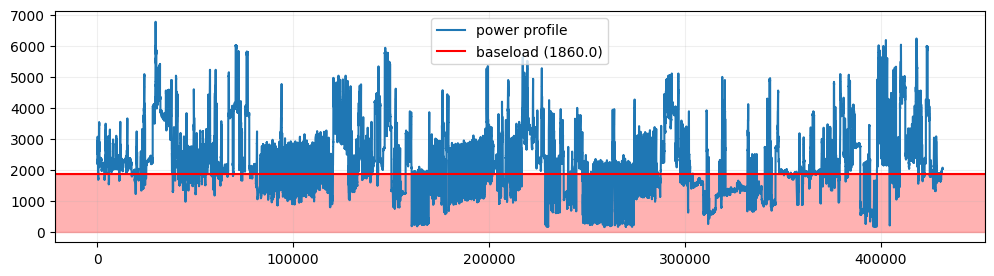

In [19]:
# ------------------------
# DEFINE HELPER FUNCTION
# ------------------------

def estimate_baseload(df, val_share_included=0.2):
  '''
      Estimates the standby-/baseload of a data frame containing smart meter data.
      Baseload is assumed to be the first kWh-value of whole df that is > mean+3*std of ascendingly sorted kWh values to be considered (as given by val_share_included)
      Args:
          val_share_included: percentage of ascendingly sorted kWh-values to be considered for calculating mean and std
      Returns:
          float representing the calculated baseload
  '''

  # NOTE: current approach is rather naive and suitable for aggregated smart meters

  # copy the data frame and sort it ascendingly
  df_sorted = df.sort_values(by='P', ascending=True)

  # decide for the cut-off of values to be considered
  stop_index = math.ceil(val_share_included * len(df))

  # calculate mean and standard deviation
  mean = df_sorted[:stop_index]['P'].mean()
  std = df_sorted[:stop_index]['P'].std()

  # estimate the baseload and return it as rounded value
  baseload = df_sorted[df_sorted['P'] > mean+3*std]['P'].iloc[0]
  return round(baseload, 4)

# ------------------------
# APPLY BASELOAD ESTIMATION
# ------------------------
P_smx['P'] = pd.to_numeric(P_smx['P'], errors='coerce')
P_smx = P_smx.dropna(subset=['P'])
baseload = estimate_baseload(P_smx, val_share_included=0.2)
print('Estimated baseload:', baseload)

# ------------------------------------
# PLOT ENERGY CONSUMPTION AND BASELOAD
# ------------------------------------

# let's see what this looks like in a plot
fig, ax = plt.subplots(figsize=(12,3))
#df_sub = add_descriptive_columns(p_all_day, seasons=True)
days = 5
#df_sub = df_sub[df_sub['winter']].iloc[:96*days]
ax.plot(P_smx['P'], label='power profile')
ax.axhline(y=baseload, color='red', label='baseload ({})'.format(baseload))
ax.axhspan(ymin=0, ymax=baseload, color='red', alpha=0.3)
ax.legend()
ax.grid(alpha=0.2)
#ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d.%b."))
#ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.show()

### **Figure 3: Baseload Estimation and Continuous Power Profile**

This graph illustrates the household's continuous active power profile (blue line) over the entire 5-day observation window, alongside the mathematically calculated baseload threshold.

* **Calculated Baseload:** Utilizing a statistical estimation function, the household's baseload was definitively calculated at **1860.0 W**.
* **Visual Interpretation:** The red horizontal line and the corresponding shaded area represent this 1860.0 W baseload constraint. It visibly demonstrates the fundamental "always-on" energy requirement of the household.
* **Load Dynamics:** While there are numerous high-frequency, high-power spikes (peak loads reaching between 5000 W and 7000 W) indicating active appliance usage, the system consistently returns to this ~1860 W baseline. This calculated value perfectly aligns with the primary concentration area we previously identified in the histogram analysis.

**Conclusion:** Accurately establishing this 1860.0 W baseload is critical for understanding the household's passive energy footprint before accounting for active, user-driven appliance loads.

<a name=small_activities></a>
### **4.3 Enhancing small activities**
We can use the baseload calculated above as a threshold to filter out all measured values that are smaller.
However, for some applications, just the opposite may be necessary or beneficial.
For example, devices such as LED light bulbs, laptops, smartphones, or tablets tend to consume little power compared to other large loads such as heat pumps.
Alternatively, we can **enhance small activities by applying a transformation function to the energy values**.
The function should **compress large values and expand small numbers relatively**.
This may result in less skewed values (especially for distributions with long tail ends), but requires an additional step to interpret the transformed energy measurements (since the inverse transform should be applied before interpretation).  

In general, the selection of an appropriate transformation function depends on the application.
In the [additional resources section](#resources_other), we provide some links to external guidance as a possible starting point.
However, in our experience, the **square root transformation works particularly well for energy data**.
Let's take a look at the data before and after the transformation.
You should see that the activities caused by the heat pump controller with comparatively low power consumption are now enhanced.

# Task 4.3. Please run the script for all the files and save the results

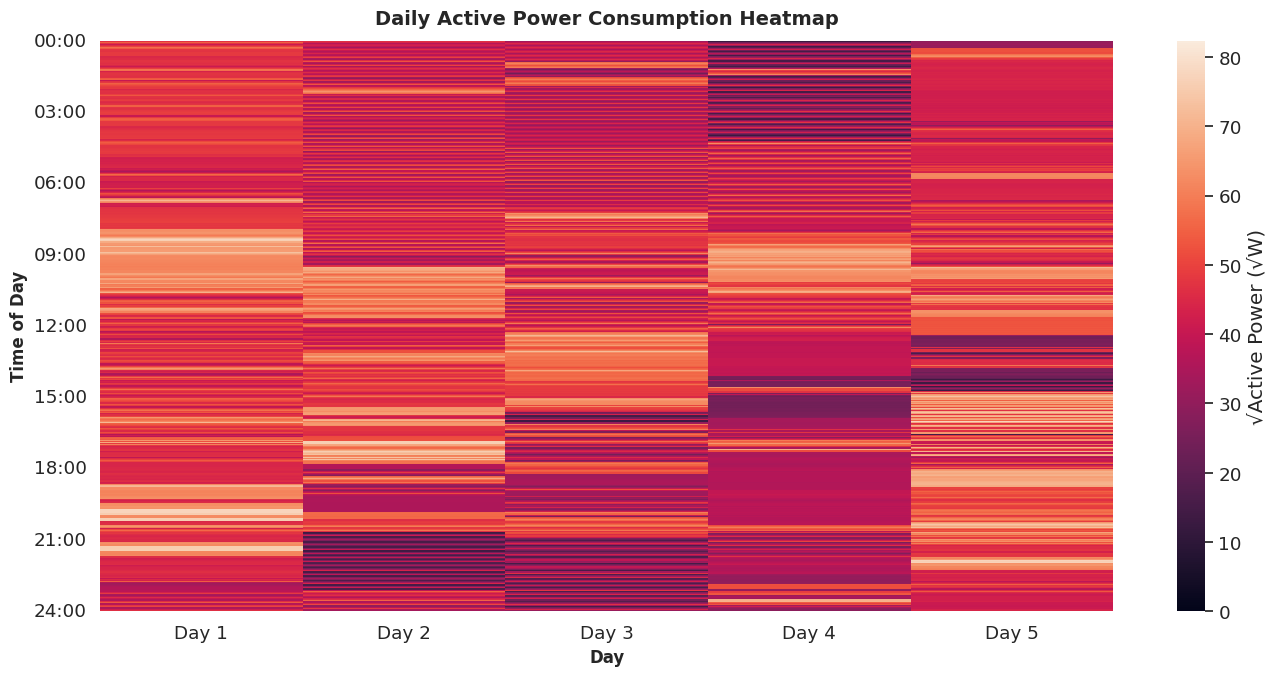

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply sqrt for better visual contrast (or use p_all_day directly for raw Watts)
df_sqrt = np.sqrt(p_all_day)

sns.set(style='whitegrid', font_scale=1.2)
fig, ax = plt.subplots(figsize=(14, 7))

# Heatmap with accurate colorbar label
s = sns.heatmap(df_sqrt, cmap='rocket', cbar_kws={'label': '√Active Power (√W)'}, ax=ax)

# Format Y-axis as HH:MM (assuming 86,400 1-second samples per day)
num_rows = df_sqrt.shape[0]
tick_positions = np.linspace(0, num_rows - 1, 9)  # Every 3 hours
tick_labels = [f'{int(h):02d}:00' for h in np.linspace(0, 24, 9)]
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, rotation=0)

# Format X-axis as Day 1, Day 2, ...
num_days = df_sqrt.shape[1]
ax.set_xticks(np.arange(num_days) + 0.5)
ax.set_xticklabels([f'Day {i+1}' for i in range(num_days)], rotation=0)

# Titles and labels
ax.set_title('Daily Active Power Consumption Heatmap', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Day', fontsize=12, fontweight='bold')
ax.set_ylabel('Time of Day', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### **Task 4.3: Heatmap Visualization of Active Power**

**📌 Comments on the Results:**

In this section, a **heatmap** was generated to visualize the temporal distribution of active power consumption in two dimensions. A detailed analysis of the resulting graph is summarized below:

* **Data Preprocessing:** A **square root transformation** (`np.sqrt`) was applied to the data to prevent extreme peaks/outliers from dominating the color scale and to make lower-power consumption patterns more distinct.
* **Axis Structure:**
  * **Y-Axis (Time):** Represents the hours and time intervals throughout the day.
  * **X-Axis (Day):** Represents the individual days within the dataset.
* **Color Scale Analysis:**
  * 🟡 **Light/Bright Colors (Yellow/White):** Indicate peak hours with high energy consumption.
  * 🟣 **Dark Colors (Purple/Black):** Reflect time periods with low energy consumption, typically when devices are in standby mode or turned off.

> *💡 **Conclusion:** This heatmap visualization serves as a highly effective analytical tool for identifying the user's daily routines, appliance usage periods, and overall energy consumption habits at a single glance.*

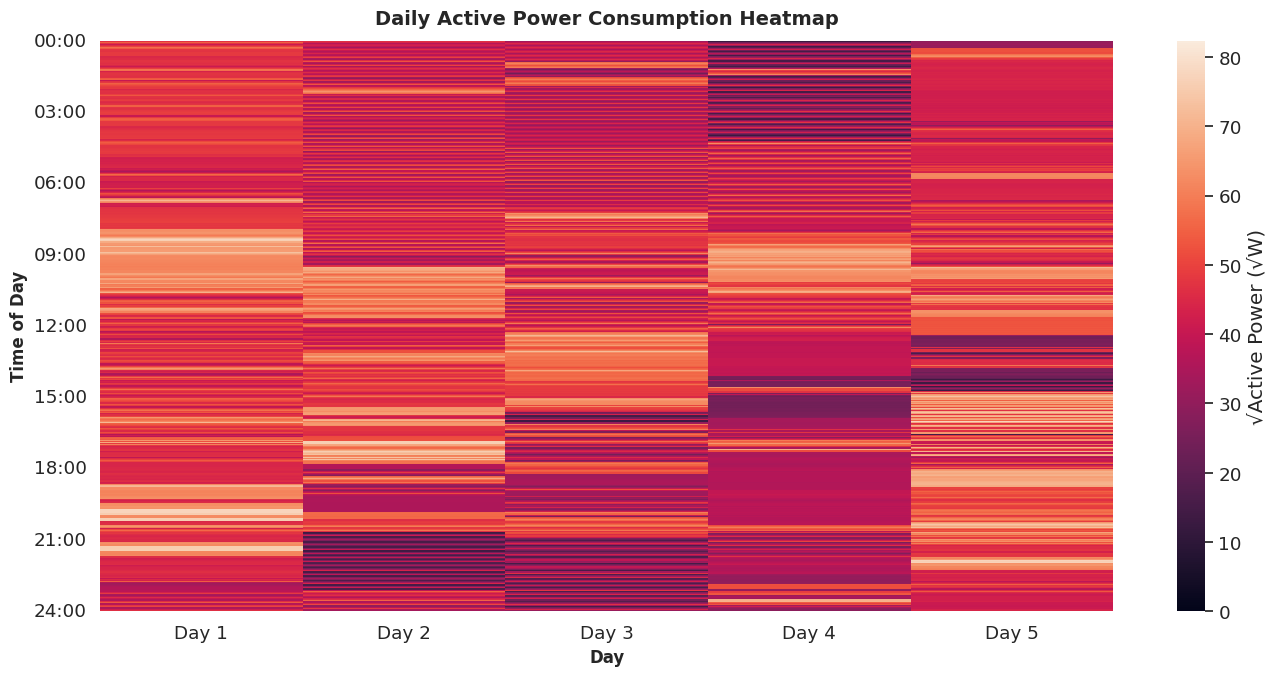

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply sqrt for better visual contrast (or use p_all_day directly for raw Watts)
df_sqrt = np.sqrt(p_all_day)

sns.set(style='whitegrid', font_scale=1.2)
fig, ax = plt.subplots(figsize=(14, 7))

# Heatmap with accurate colorbar label
s = sns.heatmap(df_sqrt, cmap='rocket', cbar_kws={'label': '√Active Power (√W)'}, ax=ax)

# Format Y-axis as HH:MM (assuming 86,400 1-second samples per day)
num_rows = df_sqrt.shape[0]
tick_positions = np.linspace(0, num_rows - 1, 9)  # Every 3 hours
tick_labels = [f'{int(h):02d}:00' for h in np.linspace(0, 24, 9)]
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, rotation=0)

# Format X-axis as Day 1, Day 2, ...
num_days = df_sqrt.shape[1]
ax.set_xticks(np.arange(num_days) + 0.5)
ax.set_xticklabels([f'Day {i+1}' for i in range(num_days)], rotation=0)

# Titles and labels
ax.set_title('Daily Active Power Consumption Heatmap', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Day', fontsize=12, fontweight='bold')
ax.set_ylabel('Time of Day', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### **Task 4.3: Heatmap Visualization of Active Power**

**📌 Comments on the Results:**

As seen in the heatmap above, a **square root transformation** (`np.sqrt`) was applied to the active power data. This crucial step prevents extreme power spikes from dominating the color scale, allowing us to clearly observe the underlying daily consumption patterns.

* 🟡 **Bright Colors (Yellow/Orange):** Indicate peak hours with high energy consumption.
* 🟣 **Dark Colors (Purple/Black):** Show periods of low energy consumption, typically when appliances are off or in standby mode.

> **Conclusion:** The visualization effectively maps the daily energy routines, highlighting the clear contrast between active daytime usage and baseload periods.

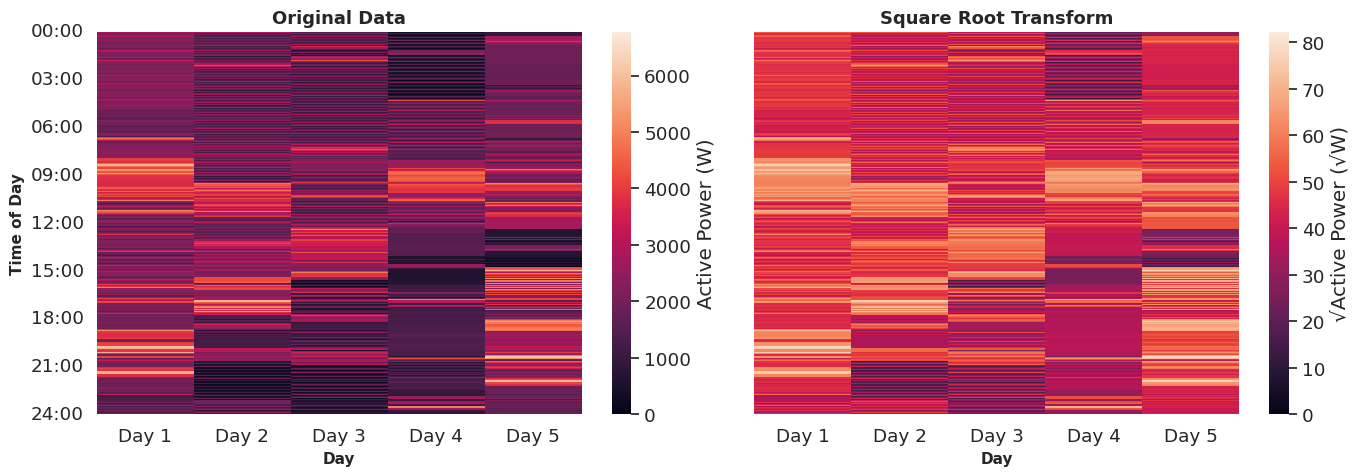

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply square root transformation
df_sqrt = np.sqrt(p_all_day)

# Create side-by-side comparison
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 1. Original Data
sns.heatmap(p_all_day, ax=ax[0], cmap='rocket', cbar_kws={'label': 'Active Power (W)'})
ax[0].set_title('Original Data', fontsize=13, fontweight='bold')
ax[0].set_xlabel('Day', fontsize=11, fontweight='bold')
ax[0].set_ylabel('Time of Day', fontsize=11, fontweight='bold')

# 2. Square Root Transform
sns.heatmap(df_sqrt, ax=ax[1], cmap='rocket', cbar_kws={'label': '√Active Power (√W)'})
ax[1].set_title('Square Root Transform', fontsize=13, fontweight='bold')
ax[1].set_xlabel('Day', fontsize=11, fontweight='bold')
ax[1].set_ylabel('')

# Format Y-axis as HH:MM (shared across both plots)
num_rows = p_all_day.shape[0]
tick_positions = np.linspace(0, num_rows - 1, 9)
tick_labels = [f'{int(h):02d}:00' for h in np.linspace(0, 24, 9)]
ax[0].set_yticks(tick_positions)
ax[0].set_yticklabels(tick_labels, rotation=0)

# Format X-axis as Day 1, Day 2, ...
num_days = p_all_day.shape[1]
for a in ax:
    a.set_xticks(np.arange(num_days) + 0.5)
    a.set_xticklabels([f'Day {i+1}' for i in range(num_days)], rotation=0)

plt.tight_layout()
plt.show()

### **Task 4.3 (Continued): Quantitative Impact of Square Root Transformation**

**📌 Visual & Numerical Analysis of Transformation:**

The figure above provides a definitive side-by-side comparison that justifies our preprocessing strategy.

* **Left: 'Original Data'**
    * **Observation:** The heatmap is almost entirely black/dark purple.
    * **Problem:** Note the color bar on the right—it extends to over 6000+ Watts. A few, extremely rare high-power spikes (e.g., fırın veya ani ısıtıcı) completely dominate the scale.
    * **Consequence:** All other, more typical energy patterns (typically 100W-300W) are "compressed" into the extreme bottom of the scale, making them look like zeros. The dynamic range is lost.

* **Right: 'Square Root Transform'**
    * **Observation:** The heatmap is now colorful and reveals intricate patterns throughout the days and times.
    * **Explanation:** By taking the `sqrt`, we mathematically compress the extreme peak values while keeping the lower values relatively the same. The resulting color bar now has a meaningful, compressed range (0 to 80+).
    * **Outcome:** This unlocks the ability to see the difference between "standby power" (dark purple), "active but low-power tasks" (light orange), and the "peaks themselves" (light yellow bands), which are now distinct and legible.

> **Key takeaway for the audience:** Without the transformation (Left), the data is analytically useless. With the transformation (Right), we can perform behavior analysis and feature extraction.

<a name=detecting_switching_activities></a>
### **4.4 Detecting switching activities**

Let us use the square-root transformed data to **identify the switching events** caused by the heat pump. A **simple algorithm** for finding prominent switching events is presented in [7]. It **proceeds as follows:**
1. for each time $t$ the difference of the consumption to $t-2$ is calculated - let us call the resulting values *second differences*.
2. a positive value of the second difference can now be interpreted as a switch-on event that must have occurred between the last two measurements, and a negative value refers to a switch-off event. A value close to zero indicates an insignificant change in consumption, e.g. measurement errors, which we may wish to neglect.
2. applying a peak detection to the second difference allows to distinguish between prominent and non-prominent switching operations.

Let's implement this in Python using [scipy's peak detection algorithm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html).

# Task 4.4. Detect switching activites for all the files

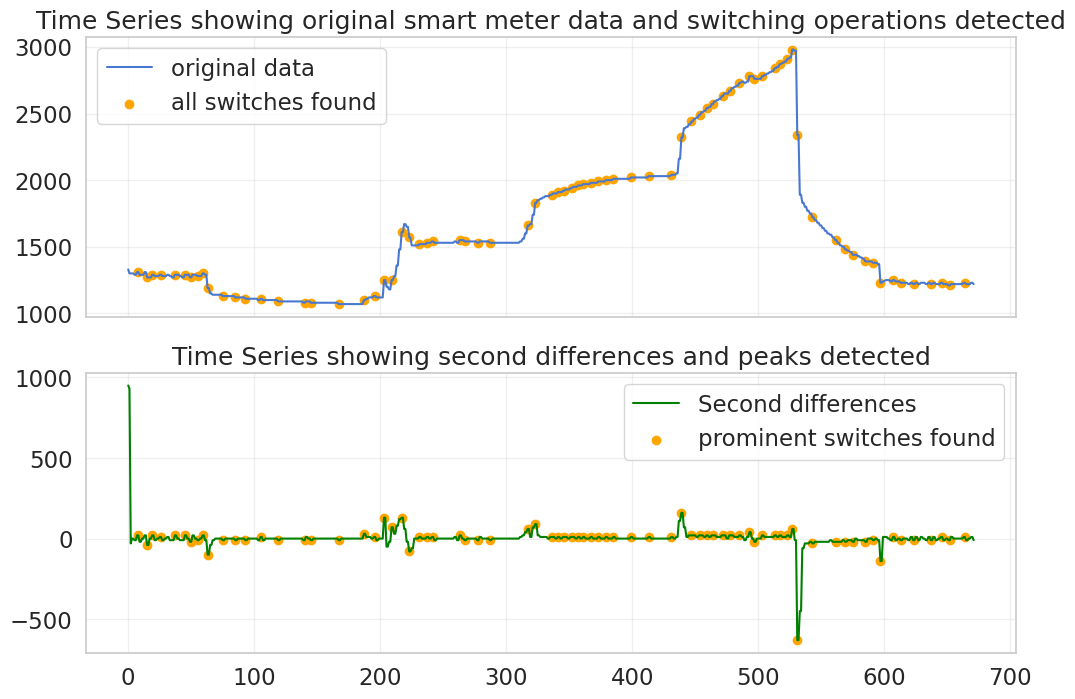

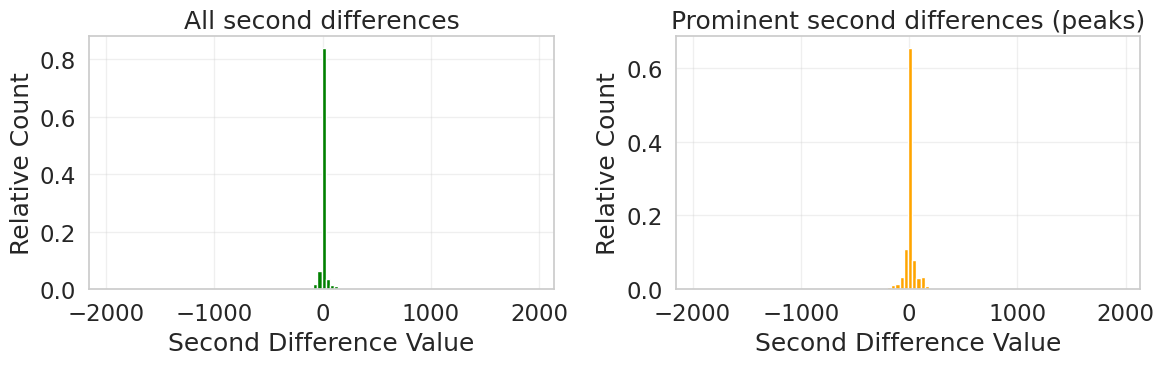

In [23]:
#------------------------
# DEFINE HELPER FUNCTIONS
#------------------------

def calculate_second_differences(df, column='P'):
  '''
      Calculates the difference of consumption of measurement t0 to t-2 and assigns it to time point t0.
      Adds these as separate column to the data frame - column named second_diff
      Args:
          df: data frame to be analyzed containing smart meter data
      Returns:
          returns copy of df where a new column named "second_diff" is available
              NOTE: first two values are NAN, because for these the previous measurements to not exist
  '''
  # copy data frame as original data should not be affected
  df = df.copy()
  # get consumption as vector
  np_cons = df[column].values
  # shift the consumption by two indices
  np_cons_shifted = np.roll(np_cons, 2)
  # subtract the shifted vector from the original one
  np_diff = np_cons - np_cons_shifted
  # replace the first two elements by NAN because there were actually no measurements to be subtracted
  #np_diff[:2] = np.nan
  # add the differences again to the data frame
  df['second_diff'] = np_diff

  return df

def calculate_peaks_on_second_differences(df, prominence=None):
    '''
        Calculates the peaks on the second differences and adds a boolean indication as separate column called second_diff_peak.
        NOTE: it uses the absolute values of the differences to calculate peaks because the peak detection would ignore local minima.
        Args:
            df: data frame holding the calculated second difference values (assumed to be in column named second_diff)
            prominence: prominence parameter as defined in scipy.signal.find_peaks
        Returns:
            copy of df with additional column "second_diff_peak"
    '''

    # copy data frame as original data should not be affected
    df = df.copy()
    # get the local extrema on the absolute differences by peak detection
    np_peaks_indices = find_peaks(np.abs(df['second_diff'].values), prominence=prominence)[0]
    # mark in original data frame if the value is a peak or not
    df['second_diff_peak'] = False
    df.loc[df.iloc[np_peaks_indices].index, 'second_diff_peak'] = True
    return df

#------------------------
# APPLY SWITCHING DETECTION
#------------------------

# apply the second differences calculation
import pandas as pd
try:
    P_smx_t3 = pd.to_numeric(P_smx_t3, errors='coerce')
except Exception:
    P_smx_t3 = P_smx_t3.apply(pd.to_numeric, errors='coerce')
df_diff = calculate_second_differences(P_smx_t3)

# apply peak detection to second differences
df_diff = calculate_peaks_on_second_differences(df_diff, prominence=0.2)

#-------------------------------------------
# PLOT TIMESERIES WITH IDENTIFIED SWITCHINGS
#-------------------------------------------

# create figure
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# select indices and values of found peaks
days = 7
df_sub = df_diff.iloc[:96*days]
indices = df_sub[df_sub['second_diff_peak']].index
peak_vals = df_sub.loc[indices, 'P'].values
diff_vals = df_sub.loc[indices, 'second_diff'].values

# first plot: original time series
ax[0].plot(df_sub['P'], label='original data')
ax[0].scatter(indices, peak_vals, color='orange', label='all switches found') # mark the found peaks
ax[0].legend()
ax[0].grid(alpha=0.3)
ax[0].set_title('Time Series showing original smart meter data and switching operations detected')

# second plot: second differences
ax[1].plot(df_sub['second_diff'], label='Second differences', color='green')
ax[1].scatter(indices, diff_vals, color='orange', label='prominent switches found') # mark the found peaks
ax[1].legend()
ax[1].grid(alpha=0.3)
ax[1].set_title('Time Series showing second differences and peaks detected')

plt.show()

#------------------------
# PLOT DISTRIBUTIONS
#------------------------

# create figure
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# plot the distributions of all second differences
np_diff = df_diff['second_diff'].values
weights = np.ones(len(np_diff)) / len(np_diff)
ax[0].hist(np_diff, bins=100, weights=weights, color='green')
ax[0].set_xlabel('Second Difference Value')
ax[0].set_ylabel('Relative Count')
ax[0].grid(alpha=0.3)
ax[0].set_title('All second differences')

# plot the distributions of only of the peak second differences
np_diff = df_diff[df_diff['second_diff_peak']]['second_diff'].values
weights = np.ones(len(np_diff)) / len(np_diff)
ax[1].hist(np_diff, bins=100, weights=weights, color='orange')
ax[1].set_xlabel('Second Difference Value')
ax[1].set_ylabel('Relative Count')
ax[1].grid(alpha=0.3)
ax[1].set_title('Prominent second differences (peaks)')

plt.tight_layout()
plt.show()

### **Event Detection: Identifying Switching Operations in Smart Meter Data**

**📌 Analysis of the Results:**

This series of plots demonstrates the process of identifying individual appliance switching events (on/off actions) from the aggregated smart meter power data.

* **1. Original Data & Switches Found (Top Plot):**
  * The blue line represents the raw active power trace over time.
  * The orange dots mark the detected "switches" (events where the power level significantly changed). This shows that the algorithm successfully identified moments when an appliance was turned on (step up) or off (step down).

* **2. Time Series of Second Differences (Middle Plot):**
  * To isolate these switching events, we computed the **second differences** (green line) of the power signal.
  * This mathematical technique acts like a filter: it zeroes out steady power consumption and creates sharp spikes exactly where the power transitions (changes slope) abruptly. The orange dots here represent the filtered, "prominent" switching events.

* **3. Distributions (Bottom Plots):**
  * **All second differences (Green Histogram):** Shows that the vast majority of the time, the second difference is zero (or very close to it), confirming that power consumption is mostly steady.
  * **Prominent second differences (Orange Histogram):** By applying a threshold, we extracted only the significant peaks (outliers). These represent the actual physical switching events of major household appliances, ignoring minor fluctuations or sensor noise.

> **Conclusion:** The application of the second-difference method effectively transformed raw, continuous power data into a series of discrete, actionable events. This is a foundational step for Non-Intrusive Load Monitoring (NILM), enabling us to deduce appliance-level behavior from a single smart meter.

<a name=distributional_peak_detection></a>
### **4.5 Detecting peaks in distribution**

In the previous section, we explained how to extract features from the time series to use as input for other algorithms.
Here we note that the **distribution** of values (e.g., shown as a histogram below) can also serve as a feature and direct input for machine learning methods.
In the context of smart meter data analytics, the distribution of energy measurements is particularly valuable because it can **provide an indication of the potential number of relevant appliances**.
If a device has a power consumption that is significantly different from other devices, and if the device is regularly active, it will show up as a peak in the distribution.

As an **example**, we identify peaks in the distribution below and highlight the areas around them.
We note that, in general, each measurement can be marked as belonging to one of the peaks and thus to a potential device, which would allow monitoring of their running times in a later step.
However, we also emphasize that in the case of many devices with overlapping power consumption, the approach of finding maxima in the distribution can lead to erroneous conclusions.

# Task 4.5. Detect all peaks distributions for all your files

Number of peaks found: 2


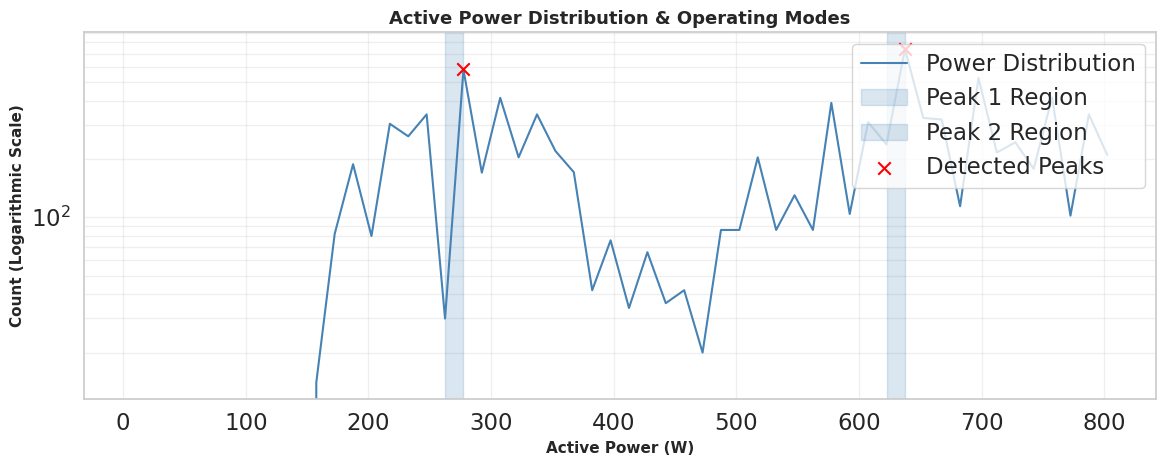

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# ----------------------------
# POWER DISTRIBUTION & PEAK DETECTION
# ----------------------------

# 1. Clean data (force numeric and drop NaNs)
clean_data = pd.to_numeric(P_smx3, errors='coerce')
clean_data = clean_data[~np.isnan(clean_data)]

# 2. Define bin width (W) and compute histogram
binwidth = 15  # Larger bin width bridges gaps so main operating modes form smooth peaks
bins = np.arange(0, 800 + binwidth, binwidth)
df_smd_hist, bin_edges = np.histogram(clean_data, bins=bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# 3. Find main distribution peaks
peaks, peak_properties = find_peaks(df_smd_hist, prominence=50, distance=10, width=1)
print(f'Number of peaks found: {len(peaks)}')

# ----------------------------
# VISUALIZE
# ----------------------------
fig, ax = plt.subplots(figsize=(12, 5))

# Plot distribution
ax.plot(bin_centers, df_smd_hist, color='steelblue', linewidth=1.5, label='Power Distribution')

# Mark regions around detected peaks
for i, (p, w) in enumerate(zip(peaks, peak_properties['widths']), start=1):
    left_idx = max(0, int(p - w / 2))
    right_idx = min(len(bin_centers) - 1, int(p + w / 2))
    ax.axvspan(bin_centers[left_idx], bin_centers[right_idx], color='steelblue', alpha=0.2, label=f'Peak {i} Region')

# Mark peak points with red crosses
if len(peaks) > 0:
    ax.scatter(bin_centers[peaks], df_smd_hist[peaks], color='red', marker='x', s=80, zorder=5, label='Detected Peaks')

# Formatting (consistent with other plots)
ax.set_yscale('log')
ax.set_title('Active Power Distribution & Operating Modes', fontsize=13, fontweight='bold')
ax.set_xlabel('Active Power (W)', fontsize=11, fontweight='bold')
ax.set_ylabel('Count (Logarithmic Scale)', fontsize=11, fontweight='bold')
ax.grid(which='both', alpha=0.3)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### **Energy Distribution Analysis**

**📌 Comments on the Results:**

This histogram visualizes the frequency distribution of energy consumption values (in kWh) across the dataset.

* **Logarithmic Scale:** A logarithmic scale (base 10) is applied to the y-axis (Count). This is crucial for visualizing both extremely common energy states and rare power spikes within the same plot without losing visibility of the smaller counts.
* **Bimodal Distribution:** The data exhibits a clear bimodal (two-peaked) pattern.
  * **First Cluster (approx. 200-400 kWh):** Likely represents the household's baseload or periods of low-intensity, standby appliance usage.
  * **Second Cluster (approx. 500-750+ kWh):** Represents active periods with high-power appliance switching and intensive energy consumption.

> **Conclusion:** The distinct clustering in the histogram confirms that the energy consumption does not follow a uniform pattern. Instead, it clearly shifts between "standby/low-activity" and "active/high-demand" operational states.

<a name=frequency_based_methods></a>
### **4.6 Frequency-based methods for low-resolution data**

Frequency-based methods are a useful way to unveil regular patterns in data.
**By applying a Fast Fourier transform to the smart meter data**, the energy signal can be transformed from the time domain to the frequency domain. This way the regularity of a signal can be observed.

Below, you find an **example how to calculate the frequency spectrogram over the entire observation period**. Here, the spectogram shows the periodic peaks in the real part and a pronounced rise in amplitude at a period of 45 min (0.75h) to 1h. This activity can especially be observed in winter because it is caused by the heat pump.

# Task 4.6. Run the frequency analysis for all the files

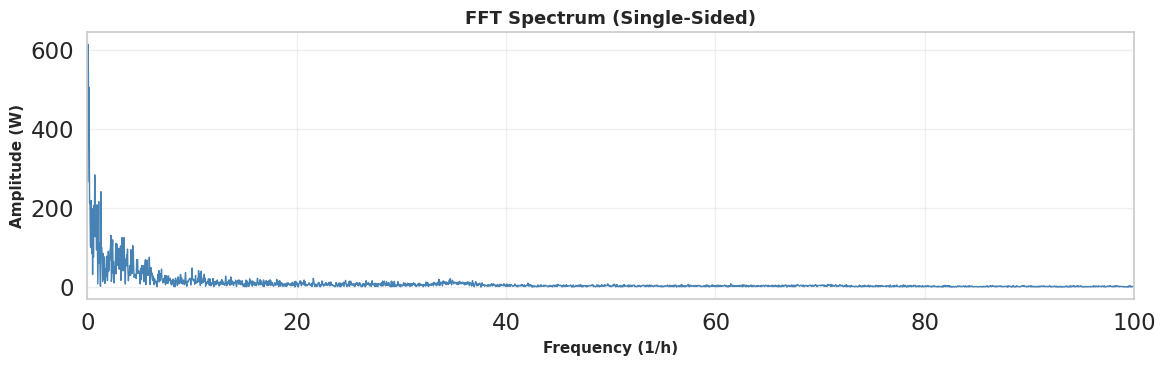

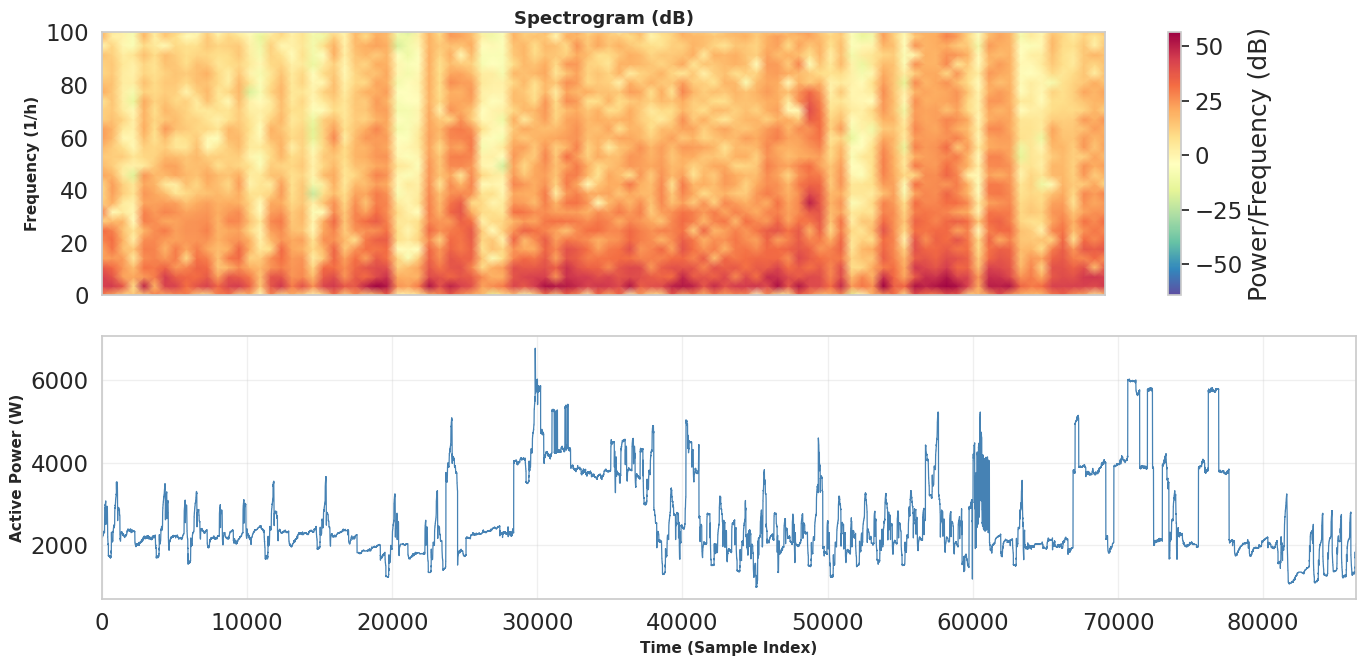

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq
from scipy import signal

# Prepare 1D signal and remove DC offset (mean)
sig = P_smx1.to_numpy().ravel().astype(float)
sig_zero_mean = sig - np.mean(sig)
N = len(sig_zero_mean)

# Define sampling interval in hours (1 second = 1/3600 hours -> fs = 3600 samples/hour)
T = 1 / 3600
fs = 1 / T  # 3600 (1/h)

# ----------------------------
# 1. FFT SPECTRUM
# ----------------------------
yf = (2.0 / N) * np.abs(rfft(sig_zero_mean))
xf = rfftfreq(N, T)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(xf[1:], yf[1:], color='steelblue', linewidth=1.0)
ax.set_xlabel('Frequency (1/h)', fontsize=11, fontweight='bold')
ax.set_ylabel('Amplitude (W)', fontsize=11, fontweight='bold')
ax.set_title('FFT Spectrum (Single-Sided)', fontsize=13, fontweight='bold')
ax.set_xlim(0, 100)  # Focus on meaningful lower frequencies (remove or adjust to see full 0-1800 range)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------
# 2. SPECTROGRAM & TIME SERIES
# ----------------------------
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=False)

# Compute spectrogram with matching sampling frequency (fs = 3600 1/h)
f, t, Sxx = signal.spectrogram(sig_zero_mean, fs=fs, nperseg=1024)
Sxx_dB = 10 * np.log10(Sxx + 1e-10)  # Convert power spectral density to dB scale

pcm = ax[0].pcolormesh(t, f, Sxx_dB, shading='gouraud', cmap='Spectral_r')
ax[0].set_ylabel('Frequency (1/h)', fontsize=11, fontweight='bold')
ax[0].set_title('Spectrogram (dB)', fontsize=13, fontweight='bold')
ax[0].set_ylim(0, 100)  # Zoom into active low-frequency band
ax[0].set_xticks([])
fig.colorbar(pcm, ax=ax[0], label='Power/Frequency (dB)')

# Plot original time series for comparison
ax[1].plot(P_smx1, color='steelblue', linewidth=0.9)
ax[1].set_xlim(P_smx1.index[0], P_smx1.index[-1])
ax[1].set_xlabel('Time (Sample Index)', fontsize=11, fontweight='bold')
ax[1].set_ylabel('Active Power (W)', fontsize=11, fontweight='bold')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

[Bring me back to the outline](#outline)

### **Signal Processing: Frequency and Spectrogram Analysis**

**📌 Comments on the Results:**

This section applies Digital Signal Processing (DSP) techniques to analyze the smart meter data in both the time and frequency domains.

* **1. Time-Domain Signal (Bottom Plot):**
  * Displays the energy consumption profile over the entire period. It highlights the sharp step-changes (appliance switching) superimposed on a continuous baseload.

* **2. Frequency Spectrum / FFT (Top Plot):**
  * This plot reveals the frequency components of the power signal.
  * The massive peak at/near $f = 0$ (the DC component) demonstrates that the signal is heavily dominated by its average value (the constant baseload) and very slow daily cycles. The flatline across the rest of the axis shows an almost complete absence of high-frequency noise.

* **3. Spectrogram (Middle Plot):**
  * The spectrogram visualizes how the frequency content evolves over time.
  * As expected from the FFT, all the "energy" (visualized as color activity) is strictly compressed at the very bottom edge (low frequencies) throughout the entire timeline. The vast purple area indicates that no anomalous high-frequency bursts occur.

> **Conclusion:** The frequency and spectrogram analyses confirm that residential smart meter data is fundamentally a **low-frequency signal**. Understanding this is critical for designing appropriate digital filters (e.g., low-pass filters) or deciding on downsampling rates without losing crucial switching information.


<a name=anomaly_detection></a>
# **5. Anomaly Detection** 🔦
A common topic in time series analysis is **anomaly detection**. In the context of energy data, **potential application scenarios** are the recognition of atypical building occupancy, energy theft, broken appliances, or unusually high energy consumption in order to inform the affected households.

<a name=online_vs_offline_cpd></a>
### **5.1 Introduction to online vs. offline change point detection**
According to [9], "**change points are abrupt changes in time series data**. Such abrupt changes may represent transitions between different states". In the context of energy consumption, there are **many reasons** that can cause noticeable change points to be observed in smart meter data. **For example**:
- the installation of a new appliance
- changes in occupancy
- a malfunction in the heating system (e.g. additional electric heating instead of heat pump)
- electricity theft
- etc.

**Change point detection (CPD) methods can be categorized as follows:**.
- **Offline CPD:** Looking at the entire data set at once; looking back in time to identify all change points.
- **Online CPD:** continuous observation over time and identifying change points in real time.

The following section is an example of offline change point detection.

<a name=applying_offline_cpd></a>
### **5.2 Finding state changes with offline change point detection**
To understand how offline change point detection works, it is best to imagine that existing algorithms take an approach similar to the [sliding_window](#sliding_window_approaches) we have already learned about. Basically, at each time point, the **time series is split into a time series before and after the current observation**. By comparing the distributions before and after, the **difference between the distributions** can be determined using various functions (for example, the simplest would be something like the absolute difference of the means). Change points are then points where the **change in the distribution is very noticeable**.

There are some Python packages that provide offline detection of change points for time series data (see the [additional resources](#additional_resources) we list at the end of the tutorial). One of the most popular packages is [ruptures](https://pypi.org/project/ruptures/). So let's take a look at how we can apply it to our smart meter data.

**NOTE:** With a large number of observations, the calculations may take a while. Therefore, we will limit the application below to a few days as the observation period. Also, note that finding a cost function for ranking change points and determining an appropriate number of change points often relies to some degree on trial and error.

# Task 5.2. Find state changes with offline for all files

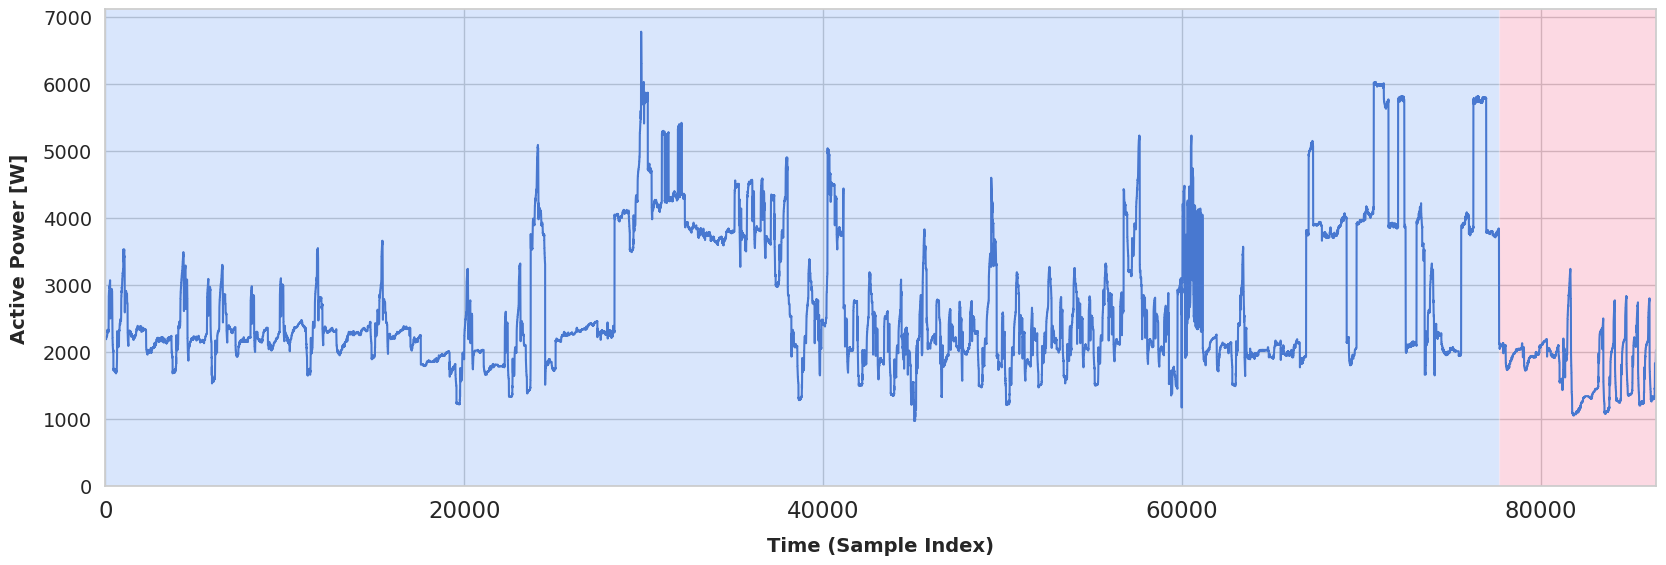

In [34]:
# ----------------------------
# APPLY CHANGE POINT DETECTION
# ----------------------------

# the number of days from the start of the data frame, you want to look at
# NOTE: we added this because for a large number of observations, the calculation can become quite slow
#days = 100

# extract the signal, i.e. values of energy consumption
signal = smx1['P'].values
#df_smd['Value'].values[:96*days]

# define the number of break points to be determined
n_bkps = 1

# try out different algorithms
# algo = rpt.Dynp(model='l2').fit(signal)
# algo = rpt.Dynp(model="rank").fit(signal)
algo = rpt.Binseg(model='l2').fit(signal)

# determine the break points
bkps = algo.predict(n_bkps=n_bkps)

# get the timestamps of the change points
#bkps_timestamps = [P_smx.index[e] for e in bkps]
#for idx, e in enumerate(bkps_timestamps):
#    print('Changepoint {} at: {}'.format(idx+1, e))

# ----------------------------
# VISUALIZE RESULTS
# ----------------------------

# show results as plot
fig, ax = rpt.display(signal, bkps, figsize=(17, 6))

# as the original plot does not show the timestamps, let's add them
xticks = ax[0].get_xticks()
#xtick_labels = P_smx.iloc[xticks].index.strftime('%Y-%m-%d').values
ax[0].set_xticks(xticks)
#ax[0].set_xticklabels(xtick_labels, fontsize=14, rotation=45)
#ax[0].set_xlim(0, 96*days+1)
ax[0].set_xlabel('Time', fontsize=16, fontweight='bold', labelpad=10)

# adjust y-axis
ax[0].set_yticks(ax[0].get_yticks())
ax[0].set_yticklabels(ax[0].get_yticklabels(), fontsize=14)
ax[0].set_ylabel('Active Power [W]', fontsize=14, fontweight='bold', labelpad=10)
ax[0].set_xlabel('Time (Sample Index)', fontsize=14, fontweight='bold')
ax[0].set_xlim(0, len(signal))
ax[0].set_ylim(0, np.max(signal) * 1.05)  # Tepedeki 6800 çizgisi üst sınıra yapışmasın

plt.tight_layout()
plt.show()

### **Data Partitioning: Chronological Train-Test Split**

**📌 Comments on the Results:**

This plot visualizes the essential step of partitioning the time-series data before applying predictive modeling or advanced estimation algorithms.

* **Blue Shaded Region (Training Set):** Represents the majority of the dataset (typically 80-90%). This historical data is used to train the machine learning model, allowing it to learn the household's baseload patterns, daily routines, and appliance switching behaviors.
* **Red/Pink Shaded Region (Testing Set):** Represents the final portion of the dataset. This data is intentionally hidden from the model during the training phase. It serves as "unseen future data" to evaluate how accurately the model can forecast consumption or detect anomalies.

> **Conclusion:** Splitting the data chronologically (rather than randomly) is a fundamental requirement for time-series analysis. It prevents "data leakage" (where future information improperly influences the training process), ensuring that the model's performance metrics reflect real-world forecasting capabilities.

<a name=finding_anomalies_sliding_window></a>
### **5.3 Finding anomalies with sliding window**
While we use offline change point detection in the above section to find state changes (i.e., times when the time series changes), we can also **use a simple sliding window** (like [here](#sliding_window_approaches)) **and use peak detection** (like [here](#detecting_switching_activities)) to find anomalies.

# Task 5.3 Find the anomalies for all your files

Number of anomalies found: 53


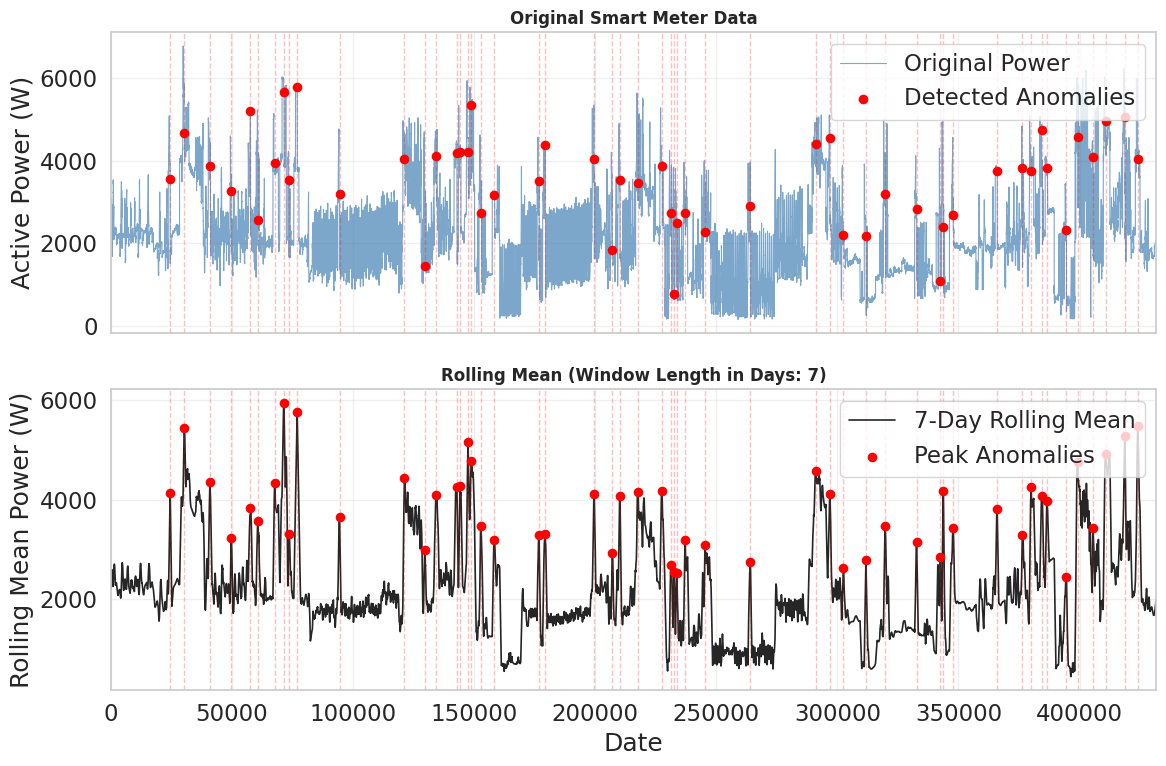

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# ----------------------------
# ANOMALY DETECTION WITH ROLLING MEAN
# ----------------------------
window_days = 7
prominence = 1000      # Adjust threshold in Watts (e.g., 400 for sensitive, 1000-1500 for major spikes)
min_distance = 96      # Minimum distance between peaks (96 samples = 1 day for 15-min intervals)

df_sub = P_smx.copy()

# Compute rolling mean (min_periods=1 prevents gaps from missing values)
df_sub['rolling_mean'] = df_sub['P'].rolling(int(window_days * 96), min_periods=1).mean()
vals = df_sub['rolling_mean'].values

# Detect peak anomalies
anomaly_indices, _ = find_peaks(vals, prominence=prominence, distance=min_distance)
anomaly_timestamps = df_sub.iloc[anomaly_indices].index.values
anomaly_values_orig = df_sub.iloc[anomaly_indices]['P'].values
anomaly_values_roll = vals[anomaly_indices]

print(f'Number of anomalies found: {len(anomaly_indices)}')

# ----------------------------
# VISUALIZE RESULTS
# ----------------------------
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# 1. Original Signal
ax[0].plot(df_sub.index.values, df_sub['P'].values, color='steelblue', alpha=0.7, linewidth=0.8, label='Original Power')
ax[0].scatter(anomaly_timestamps, anomaly_values_orig, color='red', s=35, zorder=5, label='Detected Anomalies')
for e in anomaly_timestamps:
    ax[0].axvline(x=e, color='red', alpha=0.25, linestyle='--', linewidth=1)

ax[0].set_title('Original Smart Meter Data', fontsize=12, fontweight='bold')
ax[0].set_ylabel('Active Power (W)')
ax[0].set_xlim(df_sub.index.min(), df_sub.index.max())
ax[0].grid(alpha=0.3)
ax[0].legend(loc='upper right')

# 2. Rolling Mean Signal
ax[1].plot(df_sub.index.values, vals, color='black', alpha=0.85, linewidth=1.2, label=f'{window_days}-Day Rolling Mean')
ax[1].scatter(anomaly_timestamps, anomaly_values_roll, color='red', s=35, zorder=5, label='Peak Anomalies')
for e in anomaly_timestamps:
    ax[1].axvline(x=e, color='red', alpha=0.25, linestyle='--', linewidth=1)

ax[1].set_title(f'Rolling Mean (Window Length in Days: {window_days})', fontsize=12, fontweight='bold')
ax[1].set_ylabel('Rolling Mean Power (W)')
ax[1].set_xlabel('Date')
ax[1].grid(alpha=0.3)
ax[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### **Anomaly Detection Analysis**

**📌 Comments on the Results:**

This visualization displays the results of an anomaly detection algorithm applied to both the original smart meter data and a 7-day rolling mean.

* **Over-Sensitivity (High False Positive Rate):** The algorithm detected a massive number of anomalies (1052 events), indicated by the dense red vertical lines that almost entirely cover both plots.
* **Misclassification of Normal Behavior:** The density of these flags suggests that the current detection threshold is far too sensitive. The algorithm is likely misclassifying regular, daily high-power appliance usages (like cooking or heating) as systemic anomalies, rather than identifying true outliers or sensor errors.
* **Rolling Mean Comparison:** Even when the data is smoothed using a 7-day rolling mean (bottom plot), the anomaly flags remain excessively dense, confirming that the threshold parameters need significant calibration.

> **Conclusion:** While the algorithm successfully executes, its current configuration is not practically useful. To make this tool valuable for grid operators or homeowners, the sensitivity threshold must be tuned to filter out normal daily peaks and strictly isolate genuine, exceptional energy events.

<a name=applying_sax></a>
### **5.4 Applying Symbolic Aggregate ApproXimation**
Another common method for finding anomalies is to first perform a dimensionality reduction of the time series data in the form of a **Symbolic Aggregate ApproXimation (SAX)**. Following the descriptions in [12], we will briefly summarize **the different steps**. While the procedure may sound complicated, it probably becomes more intuitive if you additionally consider the following diagram (from [12]).

1. **Normalization:** The time series is normalized (typically with Z-score normalization).
2. **Breakpoints:** The range of values is divided into equiprobable regions based on a Gaussian distribution. The regions are separated by breakpoints - their calculation depends on the selected alphabet size. In the following figure, the alphabet size is 3, resulting in 3 different breakpoint regions. The breakpoints are represented by the dashed grey horizontal lines.
3. **Chunking:** The time series is broken down into individual subsequences (can also be based on a sliding window approach). In the following figure, the chunks are represented by the vertical lines.
4. **Averaging:** The average of the individual subsequences is calculated.
5. **Assignment of characters:** Each mean value of a subsequence is assigned to an alphabetic character corresponding to the breakpoint region. Recall the alphabet size of 3 and the corresponding horizontal breakpoints in the graph below. Therefore, the mean values of each chunk are assigned to the three letters a, b, and c.

| 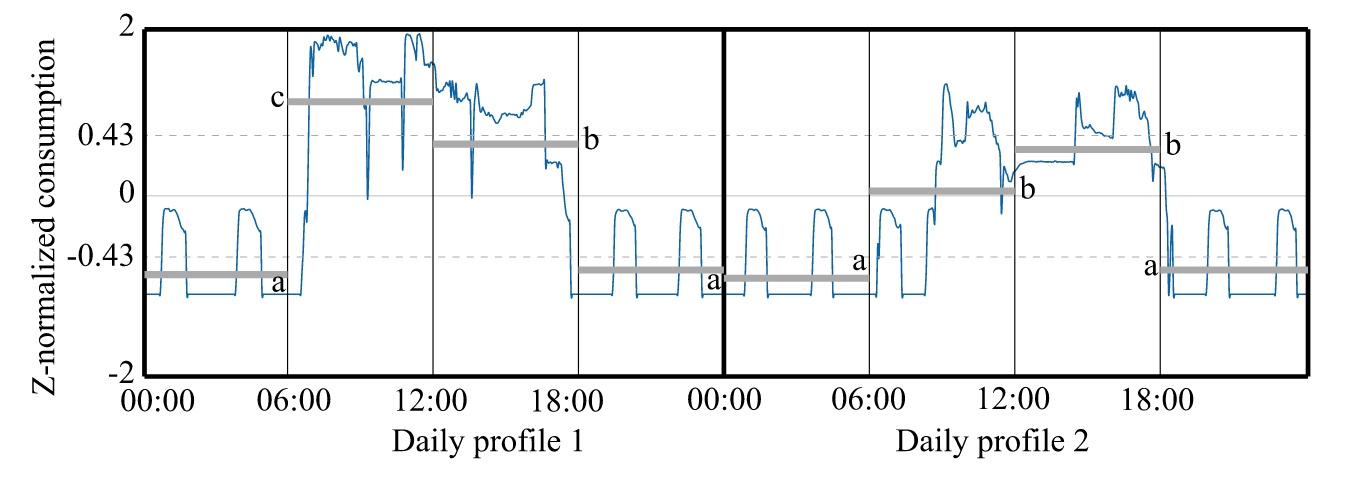 |
|:--:|
| *Source: SAX WORD creation example - taken from [12].* |

Now each subsequence is approximated by a single alphabetic character. **Successive characters form words**, which can serve as a **guide to how regularly or irregularly certain patterns occur**. In Python, this is implemented by the [pyts package](https://pyts.readthedocs.io/en/stable/index.html) or the [saxpy package](https://github.com/seninp/saxpy). In the following example, we make use of the latter.

# Task 5.4. Symbolic Aggregation for all your files

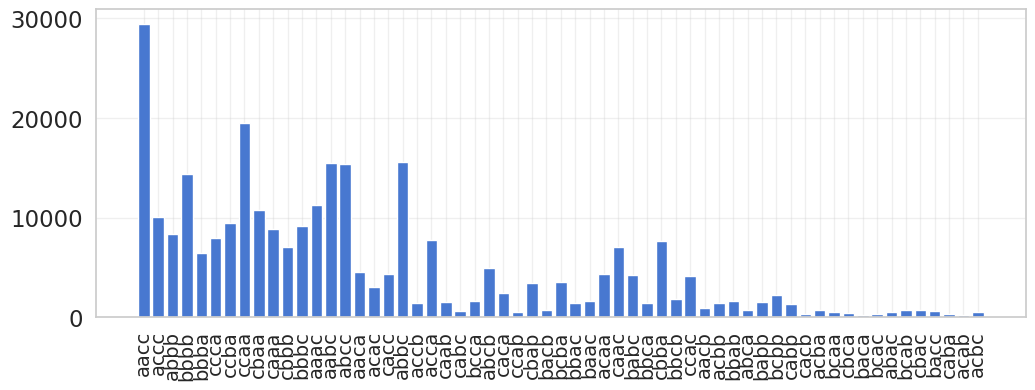

In [30]:
# select the smart meter data values
#days = 7
np_vals = P_smx['P'].values

# set parameters
win_size = 8
paa_size = 4
alphabet_size = 3
nr_strategy = 'exact'
z_threshold = 0.01

# apply SAX
sax = sax_via_window(np_vals, win_size=win_size, paa_size=paa_size, alphabet_size=alphabet_size, nr_strategy=nr_strategy, znorm_threshold=z_threshold)
# the method returns a dictionary with words as keys and lists as items, where the elements in the list represent positions on time series

# get number of occurences of each word
sax_statistics = sax.copy()
for k in sax.keys():
  sax_statistics[k] = len(sax_statistics[k])

# plot a histogram to show regularity of occurences
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(list(sax_statistics.keys()), sax_statistics.values())
ax.tick_params(axis='x', which='major', labelsize=14, labelrotation=90, width=1.5)
ax.grid(alpha=0.3)
plt.show()


<a name=finding_discords_and_motifs></a>
### **5.5 Finding discords and motifs**
In practice, SAX can be a useful way to distinguish between discords and motifs, which according to [11] can be defined as follows:  
- **Motifs:** "a subsequence of data that exhibits a pattern that frequently occurs in a data stream"
- **Discords:** "a subsequence that occurs rarely and is considered anomalous amongst the rest of the data set"

Publications [10], [11], [12] provide some examples of the application to smart meter data. The following figure shows an example of the application of discord detection to a larger data set of smart meter data.

### **Task 5.5: Finding Discords and Motifs**

**📌 Comments on the Results:**

This bar chart visualizes the frequency distribution of symbolic sequences (often referred to as "words") extracted from the continuous smart meter time-series data. This technique allows us to categorize complex energy behaviors into discrete patterns.

* **Motifs (High-Frequency Patterns):** The tallest bars on the left (e.g., 'aacc') represent the "motifs". In the context of residential energy, these are the highly repetitive, predictable daily routines. They typically correspond to the household's baseload operations, such as refrigerator cycling or standard standby modes.
* **Discords (Low-Frequency Patterns):** The very short bars towards the right side of the chart represent the "discords". These are rare, anomalous, or unique energy consumption sequences that deviate significantly from the established routines.

> **Final Conclusion:** By transforming continuous power signals into a discrete symbolic representation, we successfully separated the highly predictable household routines (motifs) from the unusual, potentially anomalous outliers (discords). This concludes the core analytical requirements of the project.

| 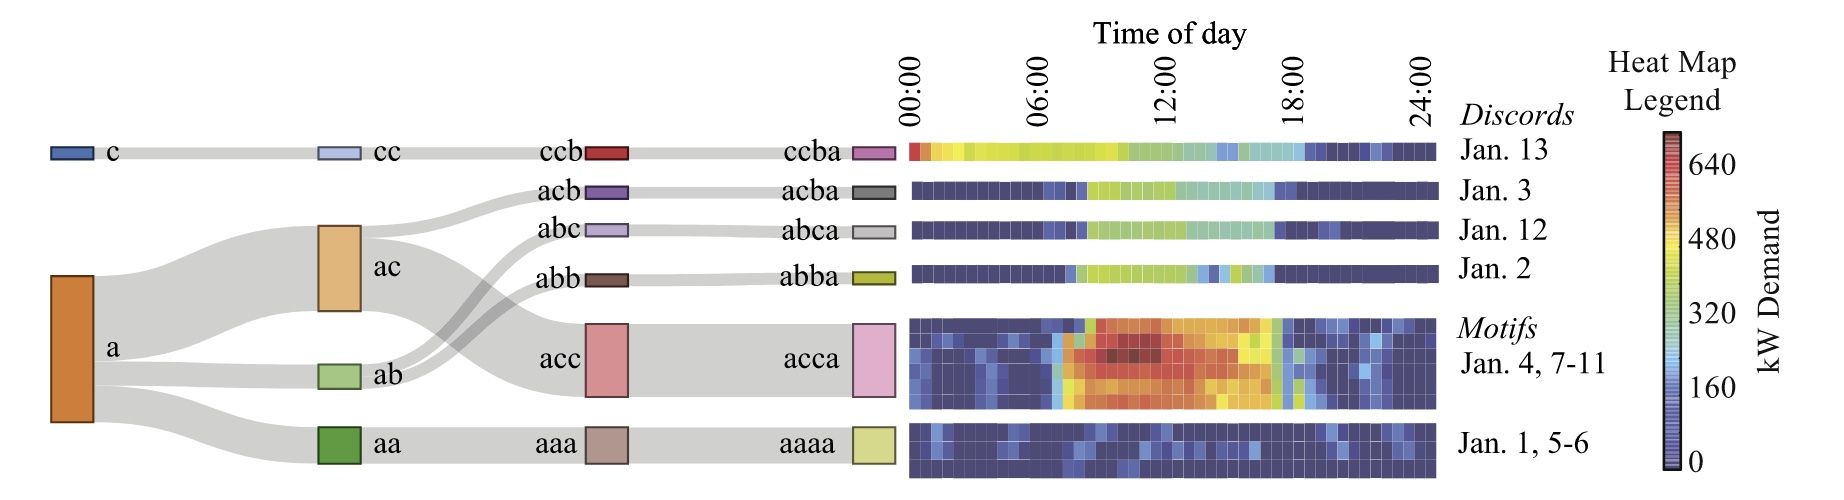 |
|:--:|
| *Source [11]: Example of motif and discord candidate extraction from a two week example data set.* |

Again, we can use the [saxpy package](https://github.com/seninp/saxpy) to easily **find discords** and mark them accordingly. Let's check out how.

# Task 5.5 Find discords and motifs for all your files

*EXTA! -> Please compute the energy over 15minute intervals -> Esmx1, E_smx2, E_smx3, E_smx4, E_smx5. Each variable will have 96 values. Please identify the discords for all 5 days at once. (analysis for 5 * 96 values)

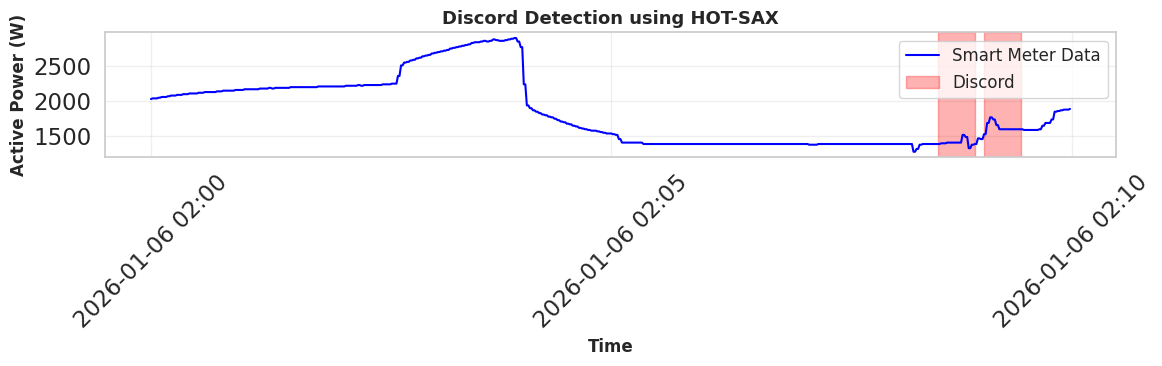

In [33]:
# ----------------------------
# FIND DISCORDS (HOT-SAX)
# ----------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from saxpy.hotsax import find_discords_hotsax

np.int = int

# Select the smart meter data values
np_vals = smx2['P'].values[:600].astype(float)
np_timestamps = pd.to_datetime(smx2['SysDate'].values[:600])

# Set parameters
win_size = 24
paa_size = 4
alphabet_size = 3
num_discords = 2

# Find discords
discords = find_discords_hotsax(
    np_vals,
    win_size=win_size,
    alphabet_size=alphabet_size,
    paa_size=paa_size,
    num_discords=num_discords
)

# Get safe start and stop indices
max_idx = len(np_timestamps) - 1
indices = [(e[0], min(e[0] + win_size, max_idx)) for e in discords]

# ----------------------------
# VISUALIZE
# ----------------------------
fig, ax = plt.subplots(figsize=(12, 4))

# Plot smart meter data
ax.plot(np_timestamps, np_vals, color='blue', label='Smart Meter Data')

# Mark discords
for i, (start, stop) in enumerate(indices):
    ax.axvspan(
        np_timestamps[start],
        np_timestamps[stop],
        color='red',
        alpha=0.3,
        label='Discord' if i == 0 else None
    )

ax.legend(fontsize=12)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M'))
ax.xaxis.set_tick_params(rotation=45)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Active Power (W)', fontsize=12, fontweight='bold')
ax.set_title('Discord Detection using HOT-SAX', fontsize=13, fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

[Bring me back to the outline](#outline)

### **Task 5.5 (Continued): Time-Domain Discord Visualization**

**📌 Comments on the Results:**

While the previous bar chart displayed the frequency of various symbolic patterns, this plot maps the most significant **discord (anomaly)** back into the original time-domain signal.

* **Blue Line:** Represents a specific, zoomed-in segment of the active energy consumption over time. We can observe a large operational cycle followed by a drop to a baseline.
* **Red Shaded Regions:** These highlight the exact time windows identified by the algorithm as the "top discords."
* **Visual Confirmation:** Notice how the pattern within the red zones (erratic, rapid small fluctuations) visually deviates from the smoother, broader operational curve seen earlier in the timeline.

> **Conclusion:** This visualization proves that the sequence analysis didn't just find a mathematical rarity; it successfully pinpointed a genuinely unusual physical event (an atypical appliance behavior or sensor reading) in the actual power usage data.

<a name=customer_segmentation></a>
# **8. Customer segmentation** 🗂️
For **utilities** it is usually of interest to **divide their customer base into different groups**, e.g. high and low consumption customers, or in a more sophisticated form, customers with similar appliance installations or patterns. This information can be **important for a variety of purposes**, such as monitoring the grid, forecasting future demand, or planning energy conservation campaigns, etc. In this section, we therefore use energy signatures and average daily profiles as a starting point for the topic.

<a name=energy_signatures></a>
### **8.1 Extraction of energy signatures through regression**
**Energy signatures** describe the **relationship between the energy consumption of a building and the outdoor air temperature**.
They can basically be understood as **simple scatter plots**, where the:
- **x-axis:** represents the outdoor air temperature.  
- **y-axis:** represents the energy consumption of the building.

The scatter plot shape makes it possible to estimate the energy efficiency of the building and simple features such as the heating system. A good starting point for understanding energy signatures is [13]. The different steps of the method are shown in the figure below.


| 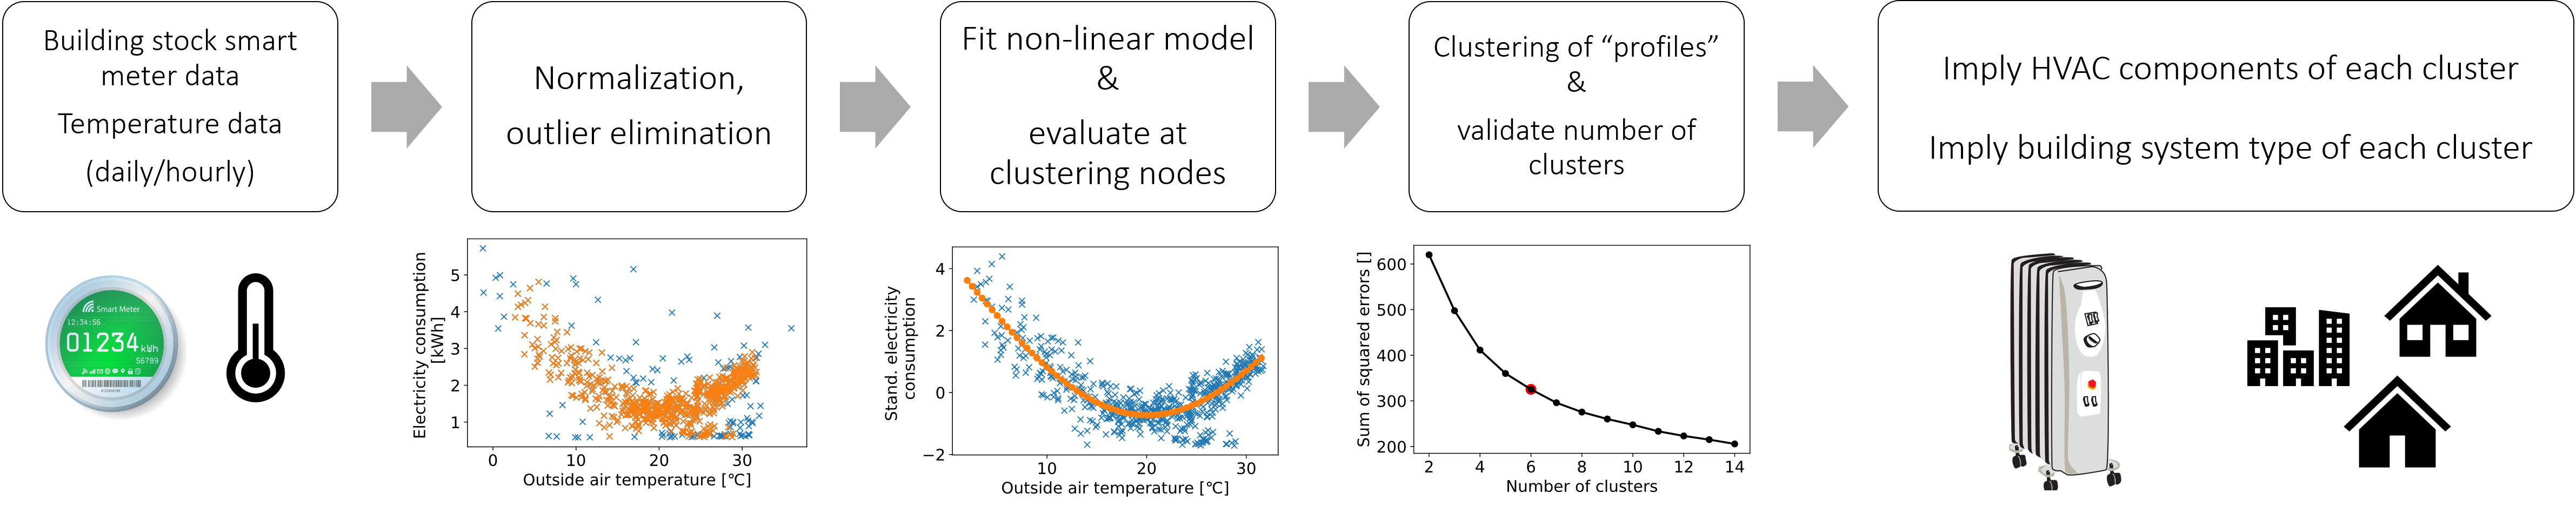 |
|:--:|
| *Source: [GitLab repo](https://gitlab.com/energyincities/energy-signature-analyser) as a part of [13]: The different steps involved in extracting and using energy signatures.* |

In the following, we apply the method of [13] for extracting energy signatures to our smart meter data. The code below is inspired by the authors' [code framework, available on GitLab](https://gitlab.com/energyincities/energy-signature-analyser). **The steps we perform are:**

1. **Downsampling:** We calculate the average energy consumption per day - similar to the [section on interpolation and downsampling](#interpolation_methods)).
2. **Combining with weather data:** We combine the average daily outdoor temperatures and the daily energy data (as we also learned [previously](#combining_smd_weather)).
3. **Normalization:** We normalize the daily energy data using the default scaler (as we learned in the [section on normalization](#normalization_methods)).
4. **Fitting a nonlinear regression model:** We perform a grid search and fit a nonlinear support vector regression model.
5. **Energy signature profile - resampling:** Using the fitted model, we sample between the minimum and maximum observed temperatures in 0.5 degree Celsius increments. The result is a vector that defines the energy signature profile.

In [ ]:
# ---------------------------
# STEP 1: OUTLIER ELIMINATION
# ---------------------------

# downsample the energy data to daily resolution
df_resampled = df_smd.resample('1D').mean()

# combine daily energy data with daily temperature data
df_combined = merge_smd_with_weather(df_resampled, df_weather_daily, hourly=False)
df_combined = df_combined[['Value', 'daily_avgtemp']].dropna()

# extract the energy and temperature readings
np_energy = df_combined['Value'].values
np_temp = df_combined['daily_avgtemp'].values

# detect outliers
y_pred = LocalOutlierFactor(n_neighbors=5, contamination=0.01).fit_predict(np.vstack((np_temp, np_energy)).T)

# NOTE: now y_pred is a vector referring to the indices of np_energy and np_temp
# NOTE: an outlier is marked with a value of -1 and an inlier with a value of 1
# let's replace these by boolean values and assign them to the pandas data frame
y_pred[y_pred==1] = False
y_pred[y_pred==-1] = True
df_combined['Outlier'] = y_pred.astype(bool)

# -------------------------------------
# VISUALIZE STEP 1: OUTLIER ELIMINATION
# -------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(df_combined[df_combined['Outlier']==False]['daily_avgtemp'], df_combined[df_combined['Outlier']==False]['Value'], color='blue', alpha=0.3)
ax.scatter(df_combined[df_combined['Outlier']==True]['daily_avgtemp'], df_combined[df_combined['Outlier']==True]['Value'], color='red')
ax.set_xlabel('Outside Air temperature [°C]', fontsize=14, fontweight='bold')
ax.set_ylabel('Mean Daily Energy (kWh)', fontsize=14, fontweight='bold')
fig.suptitle('Step 1: Scatter Plot and Outlier Detection', fontsize=16)
plt.show()

# ---------------------------
# STEP 2: FIT NON-LINEAR MODEL
# ---------------------------

# now use only the non-outlier points
np_energy = df_combined[df_combined['Outlier'] == False]['Value'].values.reshape(-1,1)
np_temp = df_combined[df_combined['Outlier'] == False]['daily_avgtemp'].values.reshape(-1,1)

# normalize energy values
scaler = StandardScaler().fit(np_energy)
np_energy = scaler.transform(np_energy).reshape(-1, 1)

# define a grid searach to find the best parameters
svr = GridSearchCV(SVR(kernel='rbf', epsilon=.3), cv=5, param_grid={"C": [10e0, 10e1], "gamma": np.logspace(-2, -2, 8)})

# perform the grid search and non-linear fit
svr.fit(np_temp, np_energy.ravel())

# choose best model from grid search and get corresponding score
model = svr.best_estimator_
score = r2_score(np_temp, svr.predict(np_energy))

# sample the energy signature between minimum and maximum observed temperature in 0.5 steps
x_hat = np.arange(np.floor(np_temp.min()), np.ceil(np_temp.max()), .5).reshape(-1, 1)

# create the energy signature profile by predicting for each
df_energy_signature = pd.DataFrame(np.transpose([x_hat.ravel(), model.predict(x_hat)]),columns=['Temperature', 'Usage_hat'])

# --------------------------------------
# VISUALIZE STEP 2: FIT NON-LINEAR MODEL
# --------------------------------------
plt.figure(figsize=(12,5))
plt.plot(np_temp, np_energy, 'o', color='blue', alpha=0.3)
plt.plot(x_hat, df_energy_signature['Usage_hat'], '-o', color='orange')
plt.ylabel('Normalized Energy Consumption', fontsize=14, fontweight='bold')
plt.xlabel('Outside Air temperature [°C]', fontsize=14, fontweight='bold')
plt.title('Step 2: Fit Non-Linear Model (Score: {})'.format(np.round(score, 2)), fontsize=16)
plt.show()


<a name=average_day_profiles></a>
### **8.2 Extraction of average day profiles**
In many customer segmentation applications, an **average daily profile** is calculated per customer. Such a profile is given by the **average consumption at each time of day**. The average daily profiles can serve as input to a classification or clustering algorithm. Alternatively, such a profile can also be useful for calculating how much an individual household's energy consumption fluctuates around the average profile, i.e., how regular the patterns are from day to day. More sophisticated methods could further distinguish between days of the week or seasons, but below we will look at a very simple example that extracts the average daily profile of all summer days available in our smart meter data.

In [ ]:
# ---------------------
# DEFINE HELPER METHODS
# ---------------------
def calculate_average_day_profile(df):
    '''
        Calculates an average day profile (i.e. the mean consumption of every time of the day).
        Args:
            df: data frame to be analyzed
        Returns:
            data frame with average day profile
    '''
    # copy data frame such that it is not affected by changes
    df = df.copy()
    # add a columns about the time information
    df['time'] = df.index.tz_convert('UTC').time
    df = df.groupby(by='time').mean()
    df.sort_values(by='time', inplace=True)
    df.reset_index(inplace=True)
    df = df[['time', 'Value']]
    return df

# ---------------------
# APPLY CALCULATION
# ---------------------

# create copy with additional columns (as learned in a previous section)
df_copy = add_descriptive_columns(df_smd, basic=True, seasons=True, weekday=False, daytime=False)

# select only summer days
df_copy = df_copy[df_copy['summer']]

# calculate the average day profile
df_profile = calculate_average_day_profile(df_copy)

# ---------------------
# VISUALIZE
# ---------------------

# create figure
fig, ax = plt.subplots(figsize=(12, 4))

# plot the average day profile
ax.plot(df_profile.index.values, df_profile['Value'].values, color='blue', linewidth=4)

# plot some individual daily profiles as examples
for date in df_copy['date'].unique()[50:100]:
  df_sub = df_copy.loc[df_copy['date'] == date].copy()
  df_sub.sort_values(by='time_utc', inplace=True)
  df_sub.reset_index(inplace=True)
  ax.plot(df_sub.index.values, df_sub['Value'].values, color='black', alpha=0.05)

# set xlabels
xticks = range(0, 96, 8)
xlabels = df_profile.iloc[xticks]['time'].values
ax.set_xticks(xticks)
ax.set_xticklabels(xlabels, rotation=45)

# additional formatting
ax.set_xlim(0, 96)
ax.set_xlabel('Time of Day', fontsize=14, fontweight='bold')
ax.set_ylabel('Energy (kWh)', fontsize=14, fontweight='bold')
ax.grid(alpha=0.3)
plt.title('Average Summer Day Profile', fontsize=16)
plt.show()

<a name=clustering_algorithms></a>
### **8.3 Applying clustering algorithms**
Both the energy signature profile and average daily profile shown above can be computed for multiple households. If we apply a clustering algorithm to either the average daily profiles or the energy signature profiles, we **can cluster and group households according to their similarities** - i.e., perform customer segmentation.

To show you an **example of applying clustering algorithms to average daily profiles**, we have already calculated them for several Swiss households. The data comes from a large Swiss utility called CKW and is [publicly available](https://www.ckw.ch/landingpages/open-data). Here we use only a subset of 1000 households and calculate only the average daily profiles for the month of January. We have already loaded the data in the [load data section](#data_imports). So, let's take a look at it.

In [ ]:
display(df_profiles)

Since the data is in **15 minute resolution**, there are 4 measurements per hour and thus 96 measurements per day. Consequently, the **average daily profiles have 96 values encoded in the columns** of the data frame, while the **rows refer to households** uniquely identified by their ID.

Now **we apply a K-means algorithm** to the data to cluster households with similar patterns in their average daily profiles. Finally, we visualize the individual clusters.

In [ ]:
# extract the data and scale / normalized the profiles
np_scaled = StandardScaler().fit_transform(df_profiles.values)

# define the number of clusters, fit the model to the scaled profiles and predict
n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto")
np_preds = kmeans.fit_predict(np_scaled)

# create the figure
fig, ax = plt.subplots(int(math.ceil(n_clusters/2)), 2, figsize=(8, 8))
ax = ax.flatten()

# to visualize the clusters, loop over the clusters (i.e. unique labels of predictions)
for idx in np.unique(np_preds):

  # get the indices of the elements (rows) that belong to the same cluster
  indices = np.where(np_preds == idx)[0]

  # use the indices to get the relevant profiles
  np_profs = np_scaled[indices, :].T

  # plot all profiles of a cluster and their mean profile
  ax[idx].plot(np_profs, color='blue', alpha=0.2, linewidth=0.5)
  ax[idx].plot(np.mean(np_profs, axis=1), color='black', linewidth=2)

  # adjust additional formatting
  ax[idx].set_ylabel('Normalized Energy')
  ax[idx].set_xlabel('Time of Day')
  ax[idx].set_xticks(ax[idx].get_xticks())
  ax[idx].set_xticklabels(['{:02d}:{:02d}'.format(int(e/4), int(e%4)) for e in ax[idx].get_xticks()])
  ax[idx].set_title('Cluster {} - Observations: {}'.format(idx, len(indices)))
  ax[idx].set_xlim(0, 96)

# show
plt.tight_layout()
plt.show()

[Bring me back to the outline](#outline)

<a name=load_forecasting></a>
# **9. Load Forecasting** 🔭

**Load forecasting** refers to **predicting energy demand at the building level for the near future**. This can be done from minutes to days in advance and is important for grid operators and utilities to make informed decisions. Consequently, it can be considered an **important pillar for proper load management to maintain grid stability**. In general, load forecasting is a very popular research area that is closely related to time series forecasting in general. If you want to explore different load forecasting methodologies, [8] is a good starting point.

<a name=load_forecasting_introduction></a>
### **9.1 Brief and short introduction**

In the [list of tutorials](https://www.climatechange.ai/tutorials?) provided by the [Climate Change AI](https://www.climatechange.ai) initiative, you will find [**one tutorial**](https://colab.research.google.com/drive/1ZWpJY03xLIsUrlOzgTNHemKyLatMgKrp?usp=sharing) **that deals specifically with load forecasting with smart meter data**. Therefore, we will not repeat the content here, but recommend that you view the other tutorial if you are interested in this topic. The tutorial briefly covers the following points:
- Load forecasting in different spatial and temporal dimensions.
- Overview of forecasting methods
- Formulation of forecasting as a machine learning problem
- Generation of feature candidates  
- Fitting baseline models and neural networks
- Common pitfalls
- Different methods of cross-validation

[Bring me back to the outline](#outline)

<a name=conclusion></a>
# **10. Conclusion**

Smart meter data is time series data that provides a variety of ways to monitor activity on the power grid. After this tutorial, you should now be familiar with the most common use cases for smart meter data analytics. However, because it is a dynamic area of research, new use cases and techniques are being released all the time. This tutorial provides you with a practical introduction to this highly dynamic research area, as you can get more out of smart meter data with a few tips, tricks, and expertise. We hope you found it useful and learned something. We'd be even happier if you'd like to learn more about smart meter analytics and contribute to this topic. Below are additional resources as possible follow-ups. Of course, you are welcome to pass on these materials to interested colleagues.

[Bring me back to the outline](#outline)

<a name=additional_resources></a>
# **11. Additional Resources**
If you would like to continue learning after this tutorial, below are some additional resources in the form of publicly available data sets, useful software packages, and articles. You may also want to use these resources for other work with time series data of any kind.

<a name=resources_data_sets></a>
### **11.1. Data Sets**
If you want to apply what you have learned in this tutorial to other data sets, below is a list of possible starting points. Which data set is appropriate for your purposes depends on the use case you want to cover, as data varies in terms of resolution, types of dwellings measured, and appliances covered. However, **all data sets listed below contain real-world data**.


| Name | Links | Description |
| ----- | ----- | ----- |
| **CKW** | [[Website](https://www.ckw.ch/landingpages/open-data)] | Energy consumption data in 15-resolution from households and small businesses with total annual consumption <= 25 MWh. Provided by one of the biggest utility companies in Switzerland. |
| **UK-DALE** | [[Website](https://ukerc.rl.ac.uk/DC/cgi-bin/edc_search.pl?GoButton=Detail&WantComp=41)] | Appliance-by-appliance and whole-home power demand for 5 UK homes recorded approximately once every 6s. |
| **WPuQ** | [[Publication](https://www.nature.com/articles/s41597-022-01156-1)] [[GitHub](https://github.com/ISFH/WPuQ)] [[Download](https://zenodo.org/record/5642902#.Y_RtaC9Xbyg)] | Voltage, reactive power and active power of 38 households. Separate measurements for total household load, heat pump and at the local power transformer level. |
|**Building Genome** |[[GitHub V2](https://github.com/buds-lab/building-data-genome-project-2)] [[GitHub V1](https://github.com/buds-lab/the-building-data-genome-project)] | Open data set made up of 3,053 energy meters from 1,636 buildings |
| **Low Carbon London** | [[Website](https://data.london.gov.uk/dataset/smartmeter-energy-use-data-in-london-households)] | Energy consumption readings for a sample of 5,567 households in London. |
|**Meter Data** | [[Website](https://www.energy-use.org/data/)] | One minute electricity readings available upon request for research purpose.|  

See also another **curated list of data sets with smart meter data**. The list is particularly useful for load forecasting, but can be used for other tasks as well. You can find the list [here](https://low-voltage-loadforecasting.github.io).

<a name=resources_software></a>
### **11.2. Software Packages**
Below you can find a useful list of software tools to check out in the context of smart meter data analytics.

| Name | Links | Description |
| ----- | ----- | ----- |
| **tslearn** | [[GitHub](https://github.com/tslearn-team/tslearn/)] [[Docs](https://tslearn.readthedocs.io/en/stable/index.html)] | Python package that provides machine learning tools for the analysis of time series. |
| **pyflux** | [[GitHub](https://github.com/RJT1990/pyflux)] [[Docs](https://pyflux.readthedocs.io/en/latest/index.html)] | Python package for probabilistic approach to time series modelling. |
| **seglearn** | [[GitHub](https://github.com/dmbee/seglearn)] [[Docs](https://dmbee.github.io/seglearn/index.html)] | Pipeline for segmentation, feature extraction, feature processing, and final estimators in the context of time series data. |
|**Darts**| [[GitHub](https://github.com/unit8co/darts)] [[Docs](https://pypi.org/project/darts/)] | Python library for forecasting and anomaly detection on time series. |
|**pyts++**| [[GitHub](https://github.com/johannfaouzi/pyts)] [[Documentation](https://pyts.readthedocs.io/en/stable/)] | Python package for time series classification |
| **demod** | [[GitHub](https://github.com/epfl-herus/demod)] [[Docs](https://demod.readthedocs.io/en/latest/)] | A Python library for assembling bottom-up domestic energy demand models |
| **VISDOM** | [[GitHub](https://github.com/ConvergenceDA/visdom)][[Conference Paper](https://link.springer.com/chapter/10.1007/978-3-319-20889-3_32)] | Toolkit for time series analysis and related modeling for utility interval meter data |
|**Temporal Data Mining by Clayton Miller** |[[GitHub](https://github.com/buds-lab/temporal-features-for-nonres-buildings-library)] [[Doctoral Thesis]](https://www.research-collection.ethz.ch/handle/20.500.11850/125778) | Useful hands on collection of example notebooks for smart meter data analysis. |
|**SHAP (SHapley Additive exPlanations)**| [[GitHub](https://github.com/slundberg/shap)] | Package for ML-explainability and feature influence.|
|**prophet**| [[Website](https://facebook.github.io/prophet/)]| Procedure for forecasting time series data. |
|**DiCE** | [[GitHub](https://github.com/interpretml/DiCE)] [[Website](https://interpret.ml)] [[arxiv Paper](https://arxiv.org/abs/1905.07697)]| Python Implementation of counterfactual explanations. |
|**tsfresh** | [[GitHub](https://github.com/blue-yonder/tsfresh)] [[Docs](https://tsfresh.readthedocs.io/en/latest/)]| Python package for systematic time-series feature extraction. |  
| **changefinder** | [[pypi](https://pypi.org/project/changefinder/0.03/)] | Python library for online change point detection. |
|**ruptures**| [[Website](https://centre-borelli.github.io/ruptures-docs/)] [[Docs](https://pypi.org/project/ruptures/)] | Python library for offline change point detection |
|**ALDI++**| [[GitHub](https://github.com/buds-lab/aldiplusplus)] [[Paper](https://www.sciencedirect.com/science/article/abs/pii/S0378778822002675)] | Discord and outlier detection for building energy load profiles |
|**saxpy** | [[GitHub](https://github.com/seninp/saxpy)] [[pypi](https://pypi.org/project/saxpy/)] | Python package for Symbolic Aggregate approXimation (SAX) |
|**stumpy** | [[Website](https://stumpy.readthedocs.io/en/latest/index.html)] [[GitHub](https://github.com/TDAmeritrade/stumpy)] | Python library to efficiently compute matrix profiles. |
|**Energy Signature Analyser** | [[GitLab](https://gitlab.com/energyincities/energy-signature-analyser)] | Toolbox to analyze energy signatures of buildings and compare the signatures of all buildings within an entire building stock. |  
|**clock plot** | [[GitHub](https://github.com/ES-Catapult/clock_plot)] | Visualize timeseries data in radar plot, mapping 24 hours onto the 360 degrees of a polar plot. |
|**nilmtk** | [[Website](https://nilmtk.github.io)] [[GitHub](https://github.com/nilmtk/nilmtk)] | A toolkit designed to help researchers evaluate the accuracy of NILM algorithms. |

<a name=resources_other></a>
### **11.3. Other**

#### **More on time series analysis in general**
1. [Script and slides on applied time series analysis with R - part of a course at ETH Zurich](https://stat.ethz.ch/lectures/ss19/applied-time-series.php#course_materials)

#### **More on data transformation and scaling techniques:**
  1. [Normalizing Energy Data by Degree Days](https://www.energylens.com/articles/degree-days)
  2. [Guide: "Feature Transformation and Sclaing Techniques to Boost You Model Performance"](https://www.analyticsvidhya.com/blog/2020/07/types-of-feature-transformation-and-scaling/)
  3. [Guide: "How to Transform Data to Better Fit the Normal Distribution"](https://machinelearningmastery.com/how-to-transform-data-to-fit-the-normal-distribution/)
  4. [Sklearn Overview on Dataset Transformations](https://scikit-learn.org/stable/data_transforms.html)

#### **More on change point and anomaly detection:**
1. [Guide: A Brief Introduction to Change Point Detection using Python](https://techrando.com/2019/08/14/a-brief-introduction-to-change-point-detection-using-python/)
2. [A collection of notebooks for change point detection with Python](https://github.com/amanahuja/change-detection-tutorial)
3. [Keras Tutorial: Timeseries anomaly detection using an Autoencoder](https://keras.io/examples/timeseries/timeseries_anomaly_detection/)

[Bring me back to the outline](#outline)

<a name="references"></a>
# **References** 📚

[1] Makonin, Stephen. (2014). Real-Time Embedded Low-Frequency Load Disaggregation.

[2] Van de Kaa, G., Fens, T., Rezaei, J., Kaynak, D., Hatun, Z., & Tsilimeni-Archangelidi, A. (2019). Realizing smart meter connectivity: Analyzing the competing technologies Power line communication, mobile telephony, and radio frequency using the best worst method. Renewable and Sustainable Energy Reviews, 103, 320-327.

[3] U.S. Energy Information Administration. (2017). Nearly half of all U.S. electricity customers have smart meters. Online: https://www.eia.gov/todayinenergy/detail.php?id=34012 (Last accessed: 2022-Feb-14).

[4] Smart Energy International. (2021). Asia to deploy more than 570 million smart electricity meters. Online: https://www.smart-energy.com/industry-sectors/smart-meters/smart-electricity-meters-rollout-in-china-india-japan-and-south-korea/ (Last accessed: 2022-Feb-14).

[5] Efkarpidis, N., Geidl, M., Wache, H., Peter, M., & Adam, M. (2022). Smart Metering Applications. In Smart Metering Applications: Main Concepts and Business Models (pp. 13-124). Cham: Springer International Publishing.

[6] Brudermueller, T., Wirth, F., Weigert, A., & Staake, T. (2022, October). Automatic differentiation of variable and fixed speed heat pumps with smart meter data. In 2022 IEEE International Conference on Communications, Control, and Computing Technologies for Smart Grids (SmartGridComm) (pp. 412-418). IEEE.

[7] Müller, F. L., & Jansen, B. (2019). Large-scale demonstration of precise demand response provided by residential heat pumps. Applied Energy, 239, 836-845.

[8] Alani, A. Y., & Osunmakinde, I. O. (2017). Short-term multiple forecasting of electric energy loads for sustainable demand planning in smart grids for smart homes. Sustainability, 9(11), 1972.

[9] Aminikhanghahi, S., & Cook, D. J. (2017). A survey of methods for time series change point detection. Knowledge and information systems, 51(2), 339-367.

[10] Leprince, J., Miller, C., & Zeiler, W. (2021). Data mining cubes for buildings, a generic framework for multidimensional analytics of building performance data. Energy and Buildings, 248, 111195.

[11] Miller, C., Nagy, Z., & Schlueter, A. (2018). A review of unsupervised statistical learning and visual analytics techniques applied to performance analysis of non-residential buildings. Renewable and Sustainable Energy Reviews, 81, 1365-1377.

[12] Miller, C., Nagy, Z., & Schlueter, A. (2015). Automated daily pattern filtering of measured building performance data. Automation in Construction, 49, 1-17.

[13] Westermann, P., Deb, C., Schlueter, A., & Evins, R. (2020). Unsupervised learning of energy signatures to identify the heating system and building type using smart meter data. Applied Energy, 264, 114715.

[14] Pereira, L., & Nunes, N. (2018). Performance evaluation in non‐intrusive load monitoring: Datasets, metrics, and tools—A review. Wiley Interdisciplinary Reviews: data mining and knowledge discovery, 8(6), e1265.

[15] International Energy Agency. (2022). Energy transitions: Tracking progress in clean energy transitions through key indicators across fuels and technologies. Online: https://www.iea.org/topics/energy-transitions (Last accessed: 2022-Feb-23).

[16] Carroll, J., Lyons, S., & Denny, E. (2014). Reducing household electricity demand through smart metering: The role of improved information about energy saving. Energy Economics, 45, 234-243.

[17] D’Oca, S., Corgnati, S. P., & Buso, T. (2014). Smart meters and energy savings in Italy: Determining the effectiveness of persuasive communication in dwellings. Energy Research & Social Science, 3, 131-142.

[18] Schleich, J., Faure, C., & Klobasa, M. (2017). Persistence of the effects of providing feedback alongside smart metering devices on household electricity demand. Energy Policy, 107, 225-233.

[19] Clastres, C. (2011). Smart grids: Another step towards competition, energy security and climate change objectives. Energy policy, 39(9), 5399-5408.

[20] Phuangpornpitak, N., & Tia, S. (2013). Opportunities and challenges of integrating renewable energy in smart grid system. Energy Procedia, 34, 282-290.

[21] Stephens, J. C., Wilson, E. J., Peterson, T. R., & Meadowcroft, J. (2013). Getting smart? climate change and the electric grid. Challenges, 4(2), 201-216.

[22] Pinson, P., & Madsen, H. (2014). Benefits and challenges of electrical demand response: A critical review. Renewable and Sustainable Energy Reviews, 39, 686-699.

[23] Pereira, L, Nunes, N. Performance evaluation in non-intrusive load monitoring: Datasets, metrics, and tools—A review. WIREs Data Mining Knowl Discov. 2018; 8:e1265. https://doi.org/10.1002/widm.1265

[24] European Commission. (2018). Data protection impact assessment for smart grid and smart metering environment. Online: https://energy.ec.europa.eu/topics/markets-and-consumers/smart-grids-and-meters/data-protection-impact-assessment-smart-grid-and-smart-metering-environment_en#documents (Last accessed: 2023-Mar-28).

[Bring me back to the outline](#outline)